In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import pyBigWig

**Finding top peak signal for cycle 1 removed calls**

In [2]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_added_removed_CT20220302.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)
DHS_metadata['start'] = DHS_metadata['start'].astype(int)
DHS_metadata['end'] = DHS_metadata['end'].astype(int)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [5]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [6]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [8]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

**Overlapping DHSs Specifically**

In [9]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
cycle1_diff_flat = cycle_np_file['diff_flat_array']

In [119]:
print(len(cycle1_diff_flat[cycle1_diff_flat<-0.5]))
print(len(cycle1_diff_flat[cycle1_diff_flat>0.5]))

34763773
7800807


In [122]:
len(cycle1_diff_flat)

2632861234

In [4]:
cycle1_diff_flat_for_plotting = cycle1_diff_flat

In [5]:
#values for bins of histogram
bins = np.round(np.arange(-1, 2, 0.025), 3)
value_for_bins = np.zeros(120)
#counting and removing delta=0 values first since this is the majority of the data
mask = (cycle1_diff_flat_for_plotting>=bins[40]) & (cycle1_diff_flat_for_plotting<bins[41])
value_for_bins[40] = len(cycle1_diff_flat_for_plotting[mask])
cycle1_diff_flat_for_plotting = cycle1_diff_flat_for_plotting[~mask]
for i in range(len(bins)-1):
    mask = (cycle1_diff_flat_for_plotting>=bins[i]) & (cycle1_diff_flat_for_plotting<bins[i+1])
    value_for_bins[i] += len(cycle1_diff_flat_for_plotting[mask])
    cycle1_diff_flat_for_plotting = cycle1_diff_flat_for_plotting[~mask]
    
value_for_bins = value_for_bins.astype(int)

Text(0.5, 1.0, 'Delta Values for Every Call in Cycle 1\nDelta Flip, Flip Size=100 Unique Delta Values')

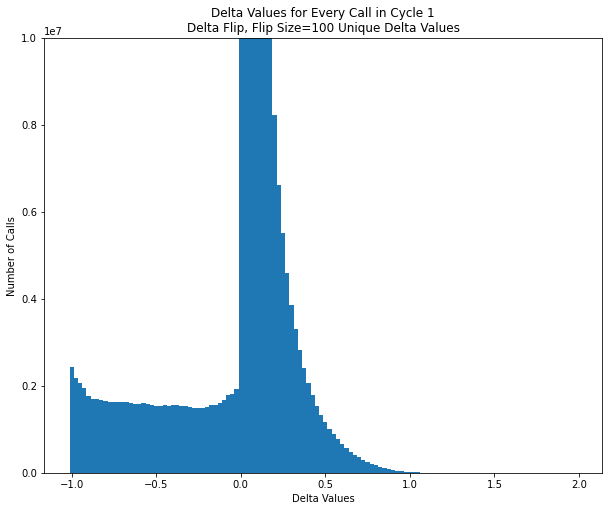

In [22]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.bar(bins, value_for_bins, width=0.025)
# sns.kdeplot(cycle1_diff_flat[:10000000])
# plt.yscale('log')
# plt.yticks([0, 1, 10, 100, 1000, ])
plt.xlabel('Delta Values')
plt.ylabel('Number of Calls')
plt.ylim([0, 10000000])
plt.title('Delta Values for Every Call in Cycle 1\nDelta Flip, Flip Size=100 Unique Delta Values')

In [11]:
#finding delta values of all flipped calls together
cycle1_flipped_call_flat_inds = np.append(added_flat_inds_all_cycles[0], removed_flat_inds_all_cycles[0])
cycle1_flipped_call_delta = cycle1_diff_flat[cycle1_flipped_call_flat_inds]

In [11]:
#gathering metadata for flipped calls
cycle1_flipped_call_DHS_inds = cycle1_flipped_call_flat_inds % n_DHSs
cycle1_flipped_call_biosample_inds = cycle1_flipped_call_flat_inds // n_DHSs

cycle1_flipped_call_DHS_chr = np.array(DHS_metadata.loc[cycle1_flipped_call_DHS_inds]['seqname'])
cycle1_flipped_call_DHS_start = np.array(DHS_metadata.loc[cycle1_flipped_call_DHS_inds]['start'])
cycle1_flipped_call_DHS_end = np.array(DHS_metadata.loc[cycle1_flipped_call_DHS_inds]['end'])

In [212]:
#full list of metadata for each DHS
DHS_metadata_chrm_arr = np.array(DHS_metadata['seqname'])
DHS_metadata_start_arr = np.array(DHS_metadata['start'])
DHS_metadata_end_arr = np.array(DHS_metadata['end'])

#finding overlapping DHSs for each flipped call
cycle1_flipped_call_overlapping_DHSs = []
t = time.time()
for chrm, start0, end0, DHS_ind in zip(cycle1_flipped_call_DHS_chr, 
                                       cycle1_flipped_call_DHS_start, 
                                       cycle1_flipped_call_DHS_end, 
                                       cycle1_flipped_call_DHS_inds):
    
    overlap_mask = ((DHS_metadata_chrm_arr==chrm) & 
                    (((DHS_metadata_start_arr <= start0) & (DHS_metadata_end_arr >= start0)) | 
                     ((DHS_metadata_start_arr >= start0) & (DHS_metadata_end_arr <= end0)) | 
                     ((DHS_metadata_start_arr <= end0) & (DHS_metadata_end_arr >= end0))))
    
    overlap_inds = np.arange(len(DHS_metadata_chrm_arr))[overlap_mask]
    overlap_inds = overlap_inds[overlap_inds!=DHS_ind]
    cycle1_flipped_call_overlapping_DHSs.append(overlap_inds)

#saving
pickle_out = open('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_overlapping_DHS_inds_for_added_and_removed_calls_fillsize100unique_cycle1_CT20220309.pickle', 'wb')
pickle.dump(cycle1_flipped_call_overlapping_DHSs, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_flipped_call_flat_inds_for_added_and_removed_calls_fillsize100unique_cycle1_CT20220309.pickle', 'wb')
pickle.dump(cycle1_flipped_call_flat_inds, pickle_out)
pickle_out.close()

In [12]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_overlapping_DHS_inds_for_added_and_removed_calls_fillsize100unique_cycle1_CT20220309.pickle', 'rb')
cycle1_flipped_call_overlapping_DHSs=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_flipped_call_flat_inds_for_added_and_removed_calls_fillsize100unique_cycle1_CT20220309.pickle', 'rb')
cycle1_flipped_call_flat_inds=pickle.load(pickle_in)

In [13]:
#how many flipped calls have overlapping DHSs
count=0
for i in cycle1_flipped_call_overlapping_DHSs:
    if len(i) > 0:
        count+=1
print(count)
print(len(cycle1_flipped_call_overlapping_DHSs))
print(count / len(cycle1_flipped_call_overlapping_DHSs))

13013
22653
0.5744493003134242


In [14]:
#finding flat inds and delta values for overlapping DHSs
cycle1_flipped_call_overlapping_flat_inds = []
cycle1_flipped_call_overlapping_delta = []
for i in range(len(cycle1_flipped_call_overlapping_DHSs)):
    flat_inds = cycle1_flipped_call_overlapping_DHSs[i] + (cycle1_flipped_call_biosample_inds[i] * n_DHSs)
    cycle1_flipped_call_overlapping_flat_inds.append(flat_inds)
    cycle1_flipped_call_overlapping_delta.append(cycle1_diff_flat[flat_inds])

In [15]:
#finding the flipped call cases where at least 1 overlapping DHS has a polar opposite 
#delta value compared to the flipped call
cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds = []
cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas = []
for flipped_delta, overlapping_deltas, local_ind in zip(cycle1_flipped_call_delta, 
                                                        cycle1_flipped_call_overlapping_delta, 
                                                        np.arange(len(cycle1_flipped_call_delta))):
    
    if ((len(overlapping_deltas[overlapping_deltas < 0]) > 0) and (flipped_delta > 0)):
        cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds.append(local_ind)
        delta = np.min(overlapping_deltas[overlapping_deltas < 0])
    elif ((len(overlapping_deltas[overlapping_deltas > 0]) > 0) and (flipped_delta < 0)):
        cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds.append(local_ind)
        delta = np.max(overlapping_deltas[overlapping_deltas > 0])
    else:
        delta = np.nan
    cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas.append(delta)
cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas = np.array(cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas)
cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds = np.array(cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds)

In [16]:
#how many overlapping calls have delta values polar opposite to flipped call
print(len(cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds))
print(len(cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds) / len(cycle1_flipped_call_delta))

8796
0.3882929413322739


In [28]:
cycle1_flipped_call_overlapping_DHSs[91]

array([1720284])

In [29]:
cycle1_flipped_call_DHS_inds[91]

1720283

In [24]:
cycle1_flipped_call_overlapping_polar_opposite_delta_local_inds

array([    1,     5,     6, ..., 22647, 22648, 22651])

In [281]:
biosample_df[biosample_df['Biosample name']=='HIPEpiC']

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
91,92,HIPEpiC,Stromal B,ENCSR000ENT,ENCLB488ZZZ,ENCBS397ENC,AG4147,LN2583,DS12684,DS12689,...,minElute,160.0,9.5,NaN,NaN,2009-10-16,206359087,0.6160,271863,271358
92,93,HIPEpiC,NaN,ENCSR000ENT,ENCLB489ZZZ,ENCBS430MWW,AG4146,LN2584,DS12689,DS12684,...,minElute,160.0,8.8,NaN,NaN,2009-10-16,33844905,0.5668,99626,99538


BigWig Signal for Flipped Call at DHS 2.5206476 in Biosample fIntestine_Lg with Delta=1.501233
Delta Flip, Flip Size=100 Unique Delta Values


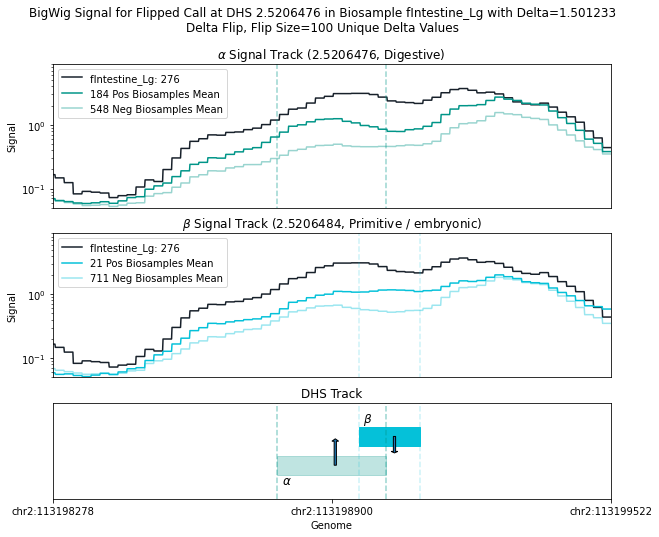

BigWig Signal for Flipped Call at DHS 10.409564 in Biosample Small_Intestine_Mucosa with Delta=1.6420196
Delta Flip, Flip Size=100 Unique Delta Values


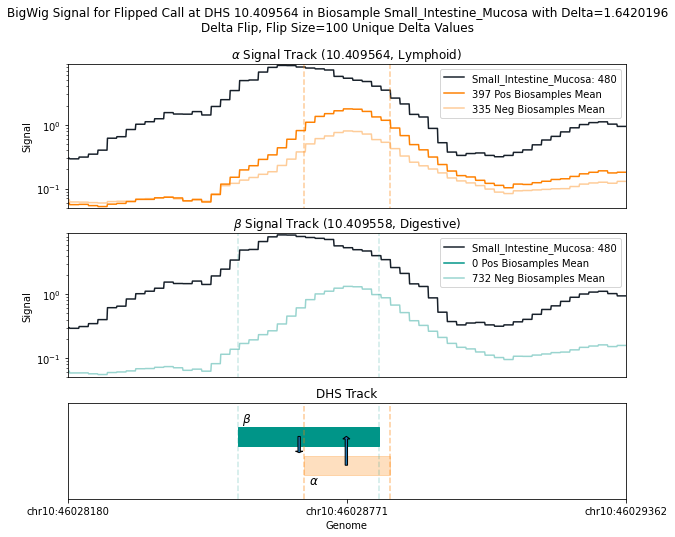

BigWig Signal for Flipped Call at DHS 6.898888 in Biosample hESCT0 with Delta=1.5508898
Delta Flip, Flip Size=100 Unique Delta Values


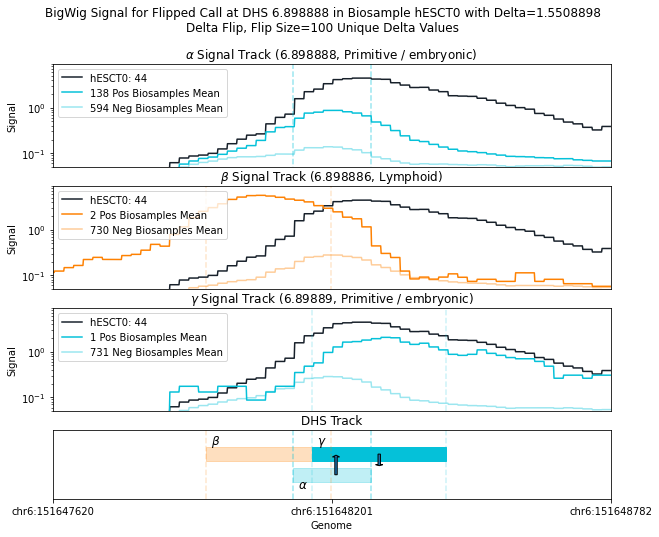

BigWig Signal for Flipped Call at DHS 8.1516948 in Biosample SAEC with Delta=1.5287768
Delta Flip, Flip Size=100 Unique Delta Values


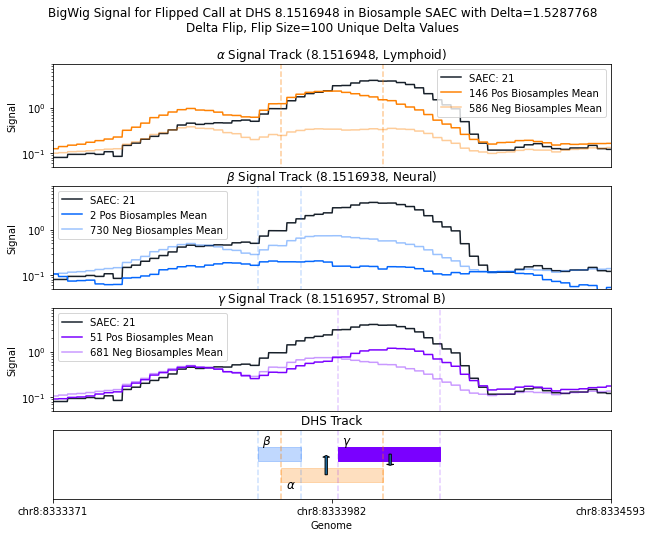

BigWig Signal for Flipped Call at DHS 10.6342634 in Biosample fKidney with Delta=1.5028335
Delta Flip, Flip Size=100 Unique Delta Values


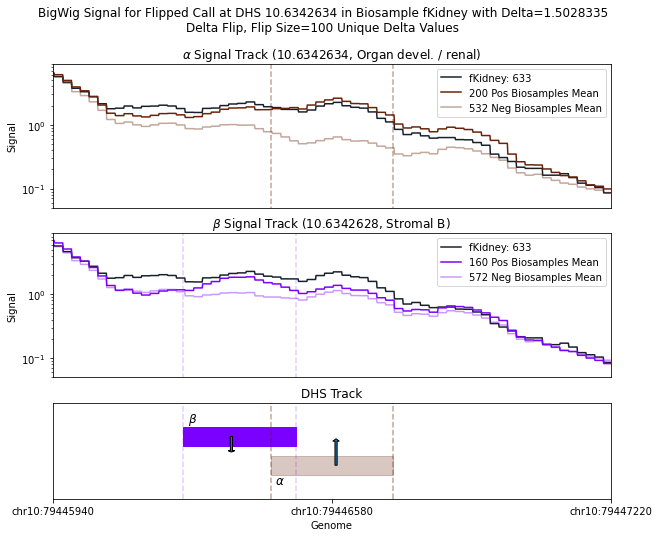

BigWig Signal for Flipped Call at DHS 10.219462 in Biosample Small_Intestine_Mucosa with Delta=1.5058297
Delta Flip, Flip Size=100 Unique Delta Values


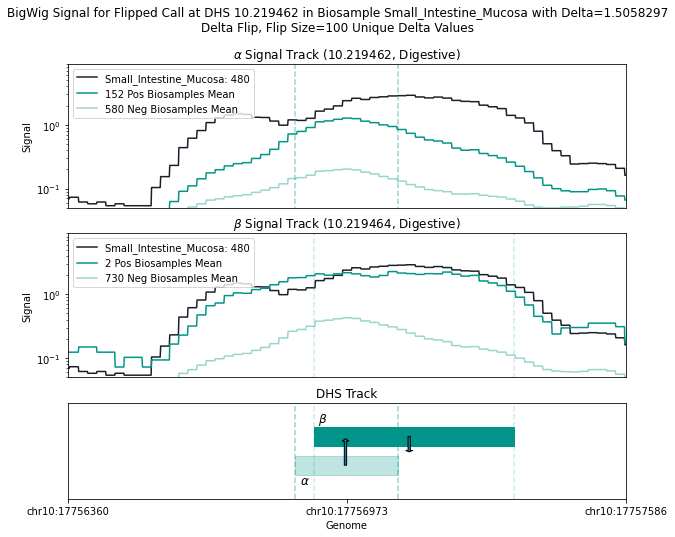

BigWig Signal for Flipped Call at DHS 1.666394 in Biosample fKidney with Delta=1.5283266
Delta Flip, Flip Size=100 Unique Delta Values


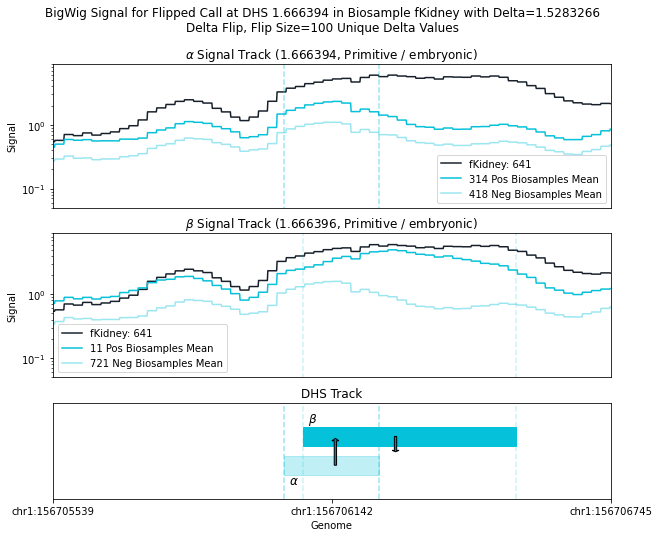

BigWig Signal for Flipped Call at DHS 5.950044 in Biosample fMuscle_leg with Delta=1.8393092
Delta Flip, Flip Size=100 Unique Delta Values


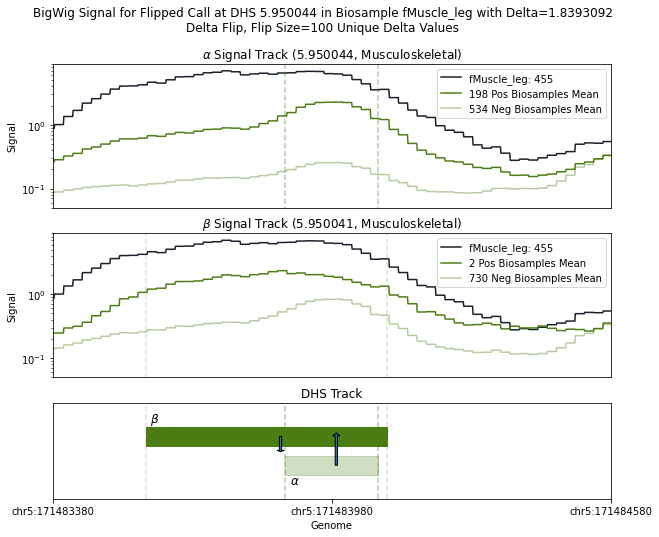

BigWig Signal for Flipped Call at DHS 15.807966 in Biosample hESCT0 with Delta=1.5046062
Delta Flip, Flip Size=100 Unique Delta Values


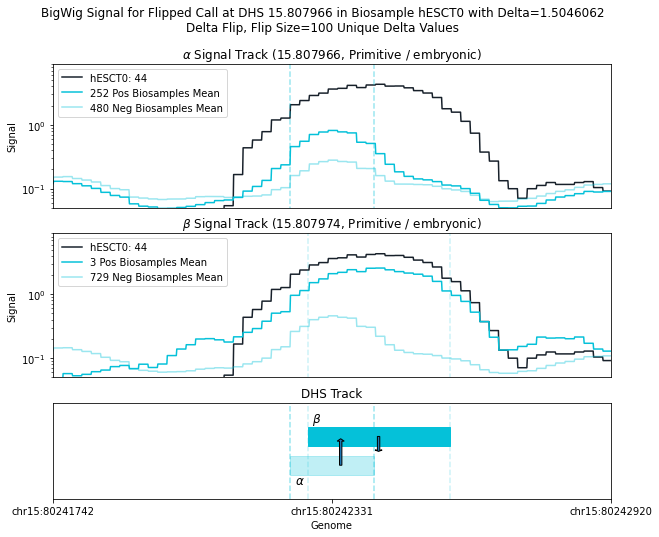

BigWig Signal for Flipped Call at DHS 3.3116691 in Biosample fMuscle_back with Delta=1.7098377
Delta Flip, Flip Size=100 Unique Delta Values


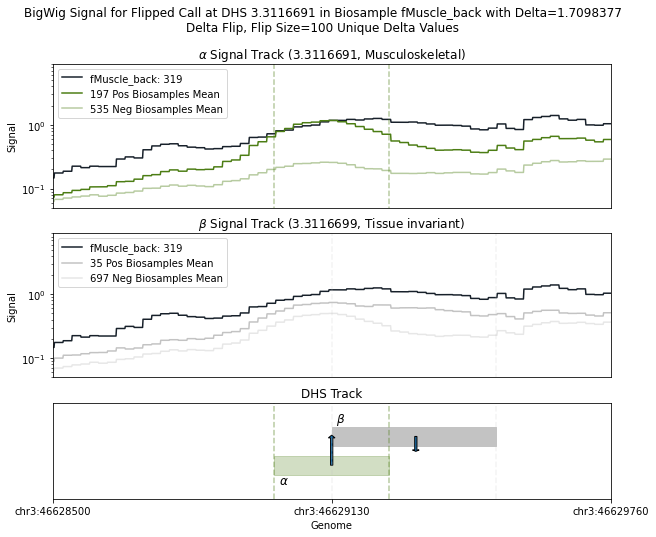

In [278]:
for i in np.argsort(cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas)[:10]:
    plotting_signal_overlapping_separate_panels(i)

BigWig Signal for Flipped Call at DHS 6.658878 in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


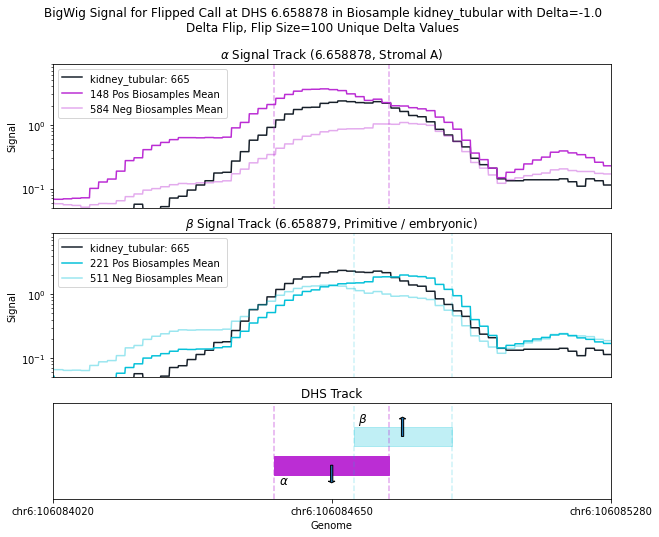

BigWig Signal for Flipped Call at DHS 5.480737 in Biosample HIPEpiC with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


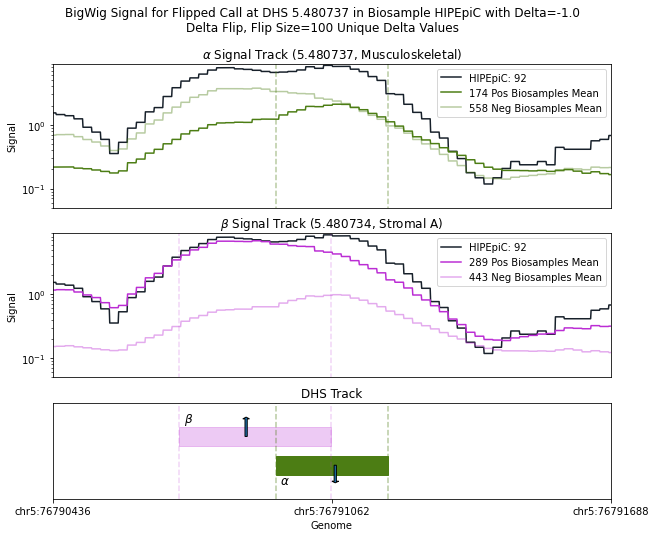

BigWig Signal for Flipped Call at DHS 6.2856669 in Biosample fLeftVentricle with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


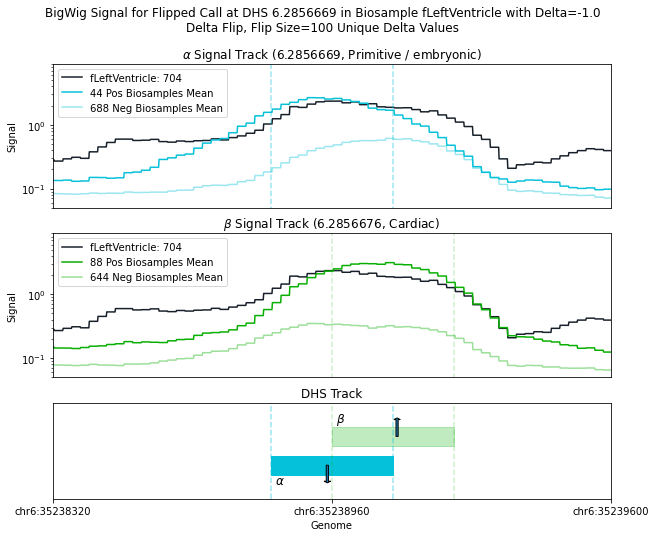

BigWig Signal for Flipped Call at DHS 3.589863 in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


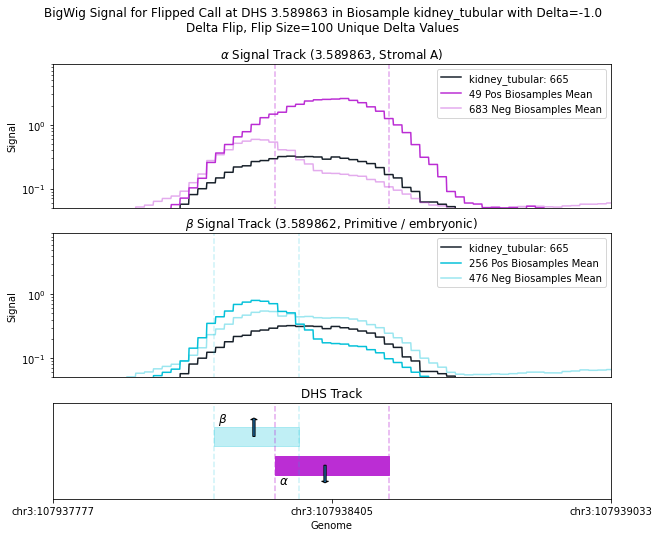

BigWig Signal for Flipped Call at DHS 14.777366 in Biosample NHA with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


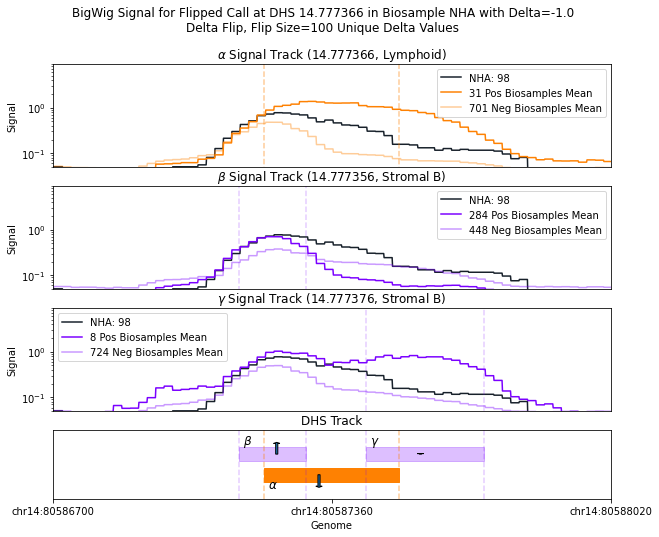

In [279]:
for i in np.argsort(-cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas)[:5]:
    plotting_signal_overlapping_separate_panels(i)

In [277]:
def plotting_signal_overlapping_separate_panels(i, buffer=500):
    #find biosample with call of interest
    biosample = cycle1_flipped_call_biosample_inds[i]
    #dhs of call of interest
    dhs = cycle1_flipped_call_DHS_inds[i]
    #chrm for DHS
    chrm = cycle1_flipped_call_DHS_chr[i]
#     dhss_inds_to_plot = DHS_inds_with_top_changes_left_to_right[:, i]
    #placing DHS of interest at the end
    dhss_inds_to_plot = np.append(dhs, cycle1_flipped_call_overlapping_DHSs[i])
    #presence or absence in original matrix
    dhss_to_plot_original_vals = cycle0_dhs_arr[biosample, dhss_inds_to_plot]
    #delta values of calls
    dhss_to_plot_delta_vals = cycle1_diff_flat[dhss_inds_to_plot + (biosample * n_DHSs)]
    dhs_of_interest_delta_val = cycle1_diff_flat[dhs + (biosample * n_DHSs)]
    #metadata for each DHS
    dhss_to_plot_df = DHS_metadata.loc[dhss_inds_to_plot]
    dhss_to_plot_comps = np.array(dhss_to_plot_df['component'])
    dhss_to_plot_comp_color = []
    for comp in dhss_to_plot_comps:
        comp_ind = np.where(comps==comp)[0]
        dhss_to_plot_comp_color.append(color[comp_ind][0])
    dhs_of_interest_name = np.array(DHS_metadata.loc[dhs]['identifier'])
    
    dhss_to_plot_start = np.array(DHS_metadata.loc[dhss_inds_to_plot]['start'])
    dhss_to_plot_end = np.array(DHS_metadata.loc[dhss_inds_to_plot]['end'])
    dhss_to_plot_summit = np.array(DHS_metadata.loc[dhss_inds_to_plot]['summit'])
    dhss_to_plot_names = np.array(DHS_metadata.loc[dhss_inds_to_plot]['identifier'])
    #placing DHS of interest in center
    first_dhs_start = dhss_to_plot_start[0]
    #not including DHS of interest
    last_dhs_end = dhss_to_plot_end[-2]
    
    dhs_of_interest_start = np.array(DHS_metadata.loc[dhs]['start'])
    dhs_of_interest_end = np.array(DHS_metadata.loc[dhs]['end'])
    
    dhs_of_interest_center = int((dhs_of_interest_start + dhs_of_interest_end)/2)
    max_dhs_dist_to_center = np.max([dhs_of_interest_center - first_dhs_start, last_dhs_end - dhs_of_interest_center])
    start = dhs_of_interest_center - buffer - max_dhs_dist_to_center
    end = dhs_of_interest_center + buffer + max_dhs_dist_to_center

    #load bw file for biosample of interest
    agnum = biosample_df.loc[biosample]['Altius Aggregation ID'][2:]
    lnnum = biosample_df.loc[biosample]['Altius Library ID']
    if lnnum[-1].isalpha():
        lnnum = lnnum[:-1]
    read_in_question_biosample_name = biosample_df.loc[biosample]['Biosample name']
    # print(agnum)
    # print(lnnum)
    filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
    bw_file = pyBigWig.open(filename)
    
    read_in_question = bw_file.values(chrm, 
                                      start, 
                                      end, 
                                      numpy=True)
    
    
    positive_biosample_average_tracks = []
    negative_biosample_average_tracks = []
    positive_num_biosamples = []
    negative_num_biosamples = []
    for dhs_for_signal in dhss_inds_to_plot:
        
        #finding all biosamples positive for call of interest and removing biosample of interest 
        other_positive_biosamples = np.where(cycle0_dhs_arr[:, dhs_for_signal]==True)[0]
        other_positive_biosamples = other_positive_biosamples[other_positive_biosamples!=biosample]
        positive_num_biosamples.append(len(other_positive_biosamples))
        
        if len(other_positive_biosamples) > 0:
            #load bw file for all positive biosamples
            base_signal_values = []
            for base_biosample in other_positive_biosamples: 
                agnum = biosample_df.loc[base_biosample]['Altius Aggregation ID'][2:]
                lnnum = biosample_df.loc[base_biosample]['Altius Library ID']
                if lnnum[-1].isalpha():
                    lnnum = lnnum[:-1]
        #         base_read_biosample_name = biosample_df.loc[base_biosample]['Biosample name']
            #     print(agnum, lnnum)
                filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
                bw_file = pyBigWig.open(filename)
                base_read = bw_file.values(chrm, 
                                           start, 
                                           end, 
                                           numpy=True)
                base_signal_values.append(base_read)
            base_signal_values = np.array(base_signal_values)
            #bp average signal
            if len(other_positive_biosamples) > 1:
                base_signal_values_ave = np.nanmean(base_signal_values, axis=0)
            else:
                base_signal_values_ave = np.squeeze(base_signal_values)
        else:
            base_signal_values_ave = np.zeros(end-start)
            base_signal_values_ave[:] = np.nan
        positive_biosample_average_tracks.append(base_signal_values_ave)
        
        
        #finding all biosamples negative for call of interest 
        negative_biosamples = np.where(cycle0_dhs_arr[:, dhs_for_signal]==False)[0]
        negative_biosamples = negative_biosamples[negative_biosamples!=biosample]
        negative_num_biosamples.append(len(negative_biosamples))
        
        if len(negative_biosamples) > 0:
            #load bw file for all negative biosamples
            negative_signal_values = []
            for negative_biosample in negative_biosamples: 
                agnum = biosample_df.loc[negative_biosample]['Altius Aggregation ID'][2:]
                lnnum = biosample_df.loc[negative_biosample]['Altius Library ID']
                if lnnum[-1].isalpha():
                    lnnum = lnnum[:-1]
        #         negative_read_biosample_name = biosample_df.loc[negative_biosample]['Biosample name']
            #     print(agnum, lnnum)
                filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
                bw_file = pyBigWig.open(filename)
                negative_read = bw_file.values(chrm, 
                                               start, 
                                               end, 
                                               numpy=True)
                negative_signal_values.append(negative_read)
            negative_signal_values = np.array(negative_signal_values)
            #bp average signal
            if len(negative_biosamples) > 1:
                negative_signal_values_ave = np.nanmean(negative_signal_values, axis=0)
            else:
                negative_signal_values_ave = np.squeeze(negative_signal_values)
        else:
            negative_signal_values_ave = np.zeros(end-start)
            negative_signal_values_ave[:] = np.nan
        negative_biosample_average_tracks.append(negative_signal_values_ave)
    
    
    #plotting
    fig, axes = plt.subplots(nrows=len(dhss_inds_to_plot)+1, 
                             figsize=(10,8), 
                             gridspec_kw={'height_ratios': np.append(np.array([3]*len(dhss_inds_to_plot)), 2)})
    fig.patch.set_facecolor('white')
    
    for ind, ax in zip(range(len(dhss_inds_to_plot)), axes):
        ax.plot(np.arange(start, end), read_in_question, color='#17202A')
        ax.plot(np.arange(start, end), positive_biosample_average_tracks[ind], color=dhss_to_plot_comp_color[ind])
        ax.plot(np.arange(start, end), negative_biosample_average_tracks[ind], color=dhss_to_plot_comp_color[ind], alpha=0.4)
    
        

        ax.legend([read_in_question_biosample_name + ': ' + str(biosample), 
                    '%s Pos Biosamples Mean' %(positive_num_biosamples[ind]),
                    '%s Neg Biosamples Mean' %(negative_num_biosamples[ind])])
        ax.set_yscale('log')
        ax.set_ylabel('Signal')
        ax.set_ylim([0.05, 9])
        if ind == 0:
            ax.set_title(r'$\alpha$ Signal Track (%s, %s)' %(dhss_to_plot_names[ind], dhss_to_plot_comps[ind]))
        elif ind == 1:
            ax.set_title(r'$\beta$ Signal Track (%s, %s)' %(dhss_to_plot_names[ind], dhss_to_plot_comps[ind]))
        else:
            ax.set_title(r'$\gamma$ Signal Track (%s, %s)' %(dhss_to_plot_names[ind], dhss_to_plot_comps[ind]))

        
    for ax, j in zip(axes, range(len(axes))):
        for ind in range(len(dhss_inds_to_plot)):
            if ind == 0:
                a=0.4
            else:
                a=0.2
            if ((ind == j) | (j == len(axes)-1)):
                ax.plot([dhss_to_plot_start[ind], dhss_to_plot_start[ind]], [0, 10], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
                ax.plot([dhss_to_plot_end[ind], dhss_to_plot_end[ind]], [0, 10], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
        
        ax.set_xlim([start, end])
        ax.set_xticks([])
#         ax.set_xticks([start, int((end+start)/2), end])
#         ax.set_xticklabels([chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])
        
    axes[-1].set_ylim([0, 1])
    axes[-1].set_yticks([])
    axes[-1].set_xlabel('Genome')
    axes[-1].set_xticks([start, int((end+start)/2), end])
    axes[-1].set_xticklabels([chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])
    axes[-1].set_title('DHS Track')
    
    for ind in range(len(dhss_inds_to_plot)):
        min_rect_base = 0.25
        if ind == 0:
            rect_base = min_rect_base
        else:
            rect_base = min_rect_base + 0.3
        if dhss_to_plot_original_vals[ind]:
            a = 1
        else:
            a = 0.25
        dhs_rect = patches.Rectangle((dhss_to_plot_start[ind], rect_base),
                                     dhss_to_plot_end[ind] - dhss_to_plot_start[ind], 
                                     0.2,
                                     alpha=a,
                                     color = dhss_to_plot_comp_color[ind])
        fig.gca().add_patch(dhs_rect)
        if ind == 0:
            plt.text(dhss_to_plot_start[ind]+10, rect_base-0.1, r'$\alpha$', fontsize=12)
        elif ind == 1:
            plt.text(dhss_to_plot_start[ind]+10, rect_base+0.25, r'$\beta$', fontsize=12)
        else:
            plt.text(dhss_to_plot_start[ind]+10, rect_base+0.25, r'$\gamma$', fontsize=12)
        
            
        
    for ind in range(len(dhss_inds_to_plot)):
        if ind == 0:
            arrow_base = 0.35
        else:
            arrow_base = 0.65
            
        axes[-1].arrow(dhss_to_plot_summit[ind], 
                  arrow_base, 
                  0, 
                  dhss_to_plot_delta_vals[ind]/6, 
                  width=5, 
                  length_includes_head=False,
                  head_length=np.abs(dhss_to_plot_delta_vals[ind]/60))
        


    
    plot_title = 'BigWig Signal for Flipped Call at DHS %s in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhs_of_interest_name, read_in_question_biosample_name, dhs_of_interest_delta_val)
    print(plot_title)
    plt.suptitle(plot_title)
    plt.show()

In [63]:
DHS_metadata[DHS_metadata['identifier']=='10.409564']

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
368012,chr10,46028680,46028862,10.409564,1.850002,397,46028770,46028750.0,46028810.0,Lymphoid


In [214]:
#most negative overlapping deltas
np.argsort(cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas)

array([   91,    21,    51, ...,  9894,  9871, 22652])

BigWig Signal at DHS 2.5206476 for Flipped Call in Biosample fIntestine_Lg with Delta=1.501233
Delta Flip, Flip Size=100 Unique Delta Values


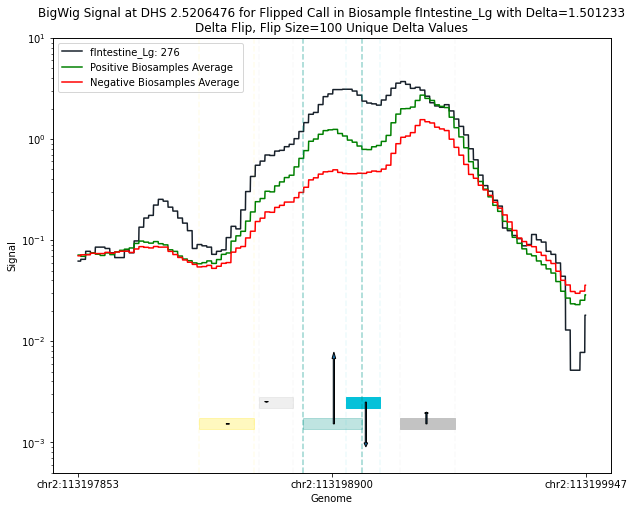

BigWig Signal at DHS 10.409564 for Flipped Call in Biosample Small_Intestine_Mucosa with Delta=1.6420196
Delta Flip, Flip Size=100 Unique Delta Values


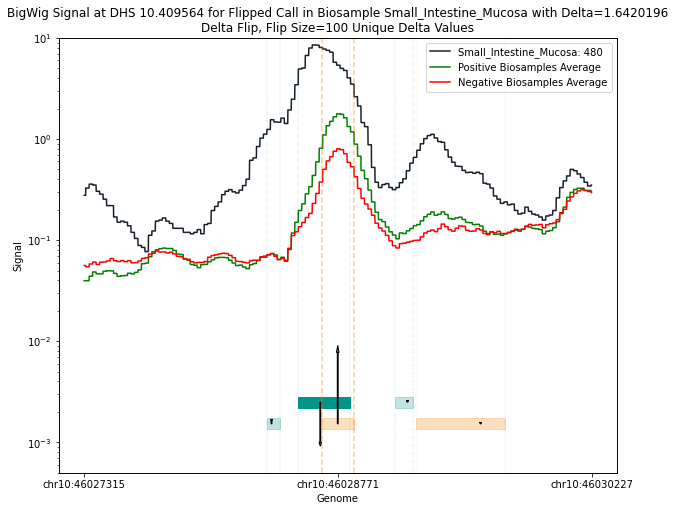

BigWig Signal at DHS 6.898888 for Flipped Call in Biosample hESCT0 with Delta=1.5508898
Delta Flip, Flip Size=100 Unique Delta Values


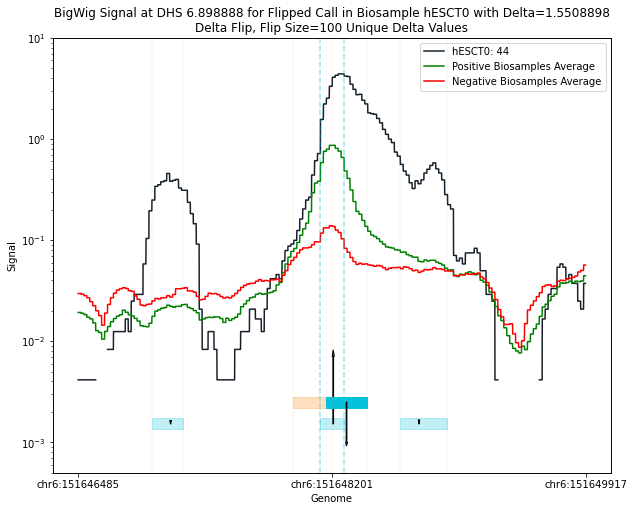

BigWig Signal at DHS 8.1516948 for Flipped Call in Biosample SAEC with Delta=1.5287768
Delta Flip, Flip Size=100 Unique Delta Values


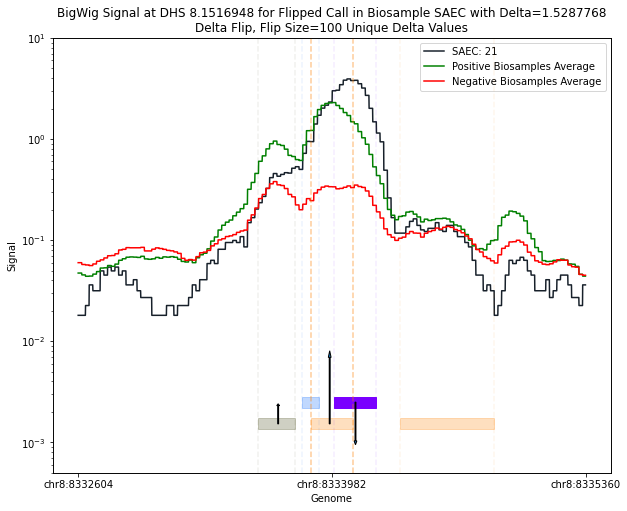

BigWig Signal at DHS 10.6342634 for Flipped Call in Biosample fKidney with Delta=1.5028335
Delta Flip, Flip Size=100 Unique Delta Values


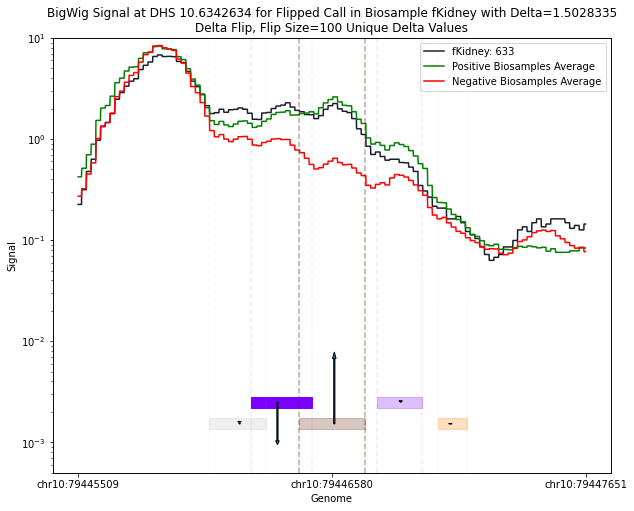

BigWig Signal at DHS 10.219462 for Flipped Call in Biosample Small_Intestine_Mucosa with Delta=1.5058297
Delta Flip, Flip Size=100 Unique Delta Values


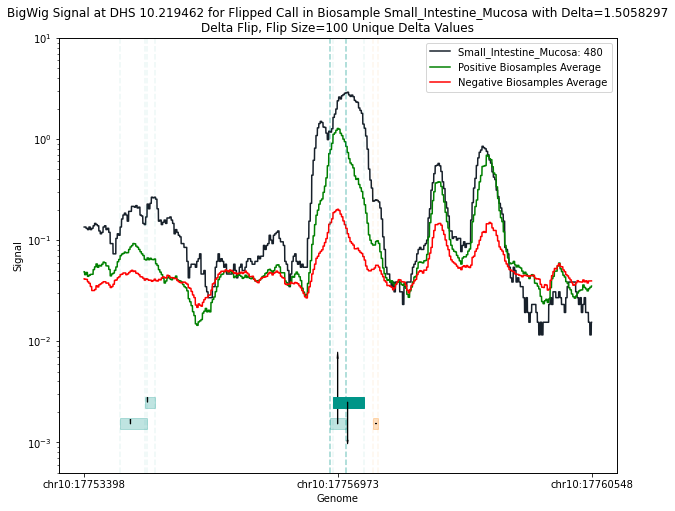

BigWig Signal at DHS 1.666394 for Flipped Call in Biosample fKidney with Delta=1.5283266
Delta Flip, Flip Size=100 Unique Delta Values


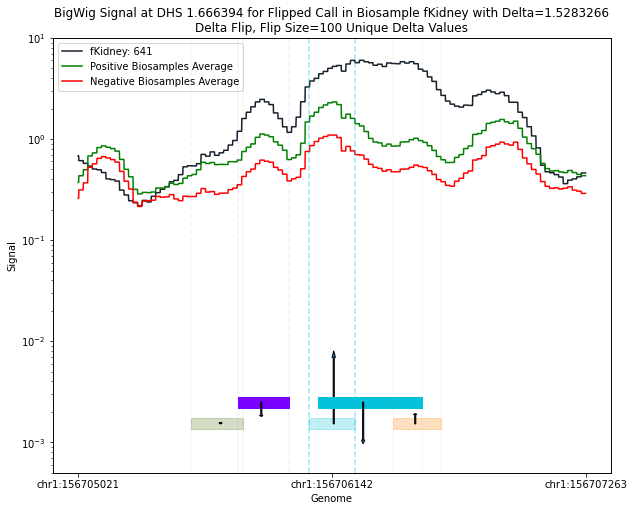

BigWig Signal at DHS 5.950044 for Flipped Call in Biosample fMuscle_leg with Delta=1.8393092
Delta Flip, Flip Size=100 Unique Delta Values


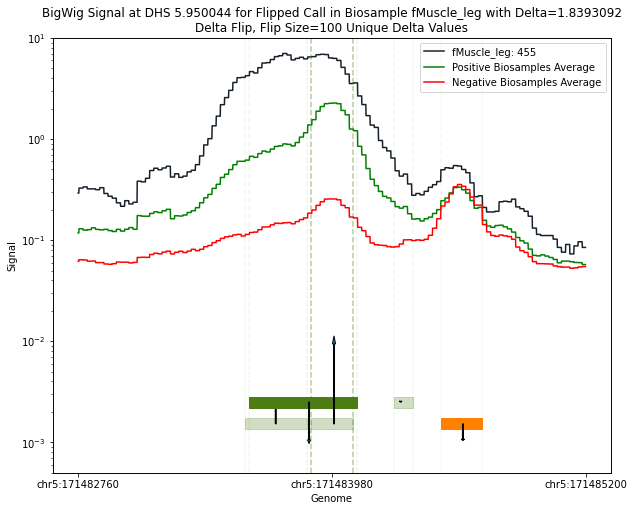

BigWig Signal at DHS 15.807966 for Flipped Call in Biosample hESCT0 with Delta=1.5046062
Delta Flip, Flip Size=100 Unique Delta Values


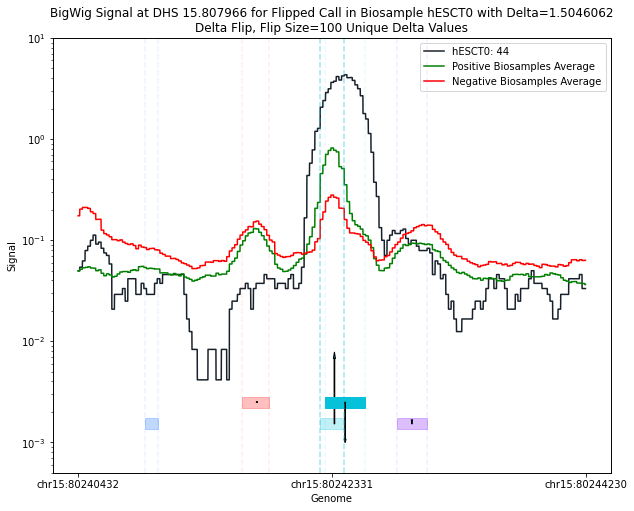

BigWig Signal at DHS 3.3116691 for Flipped Call in Biosample fMuscle_back with Delta=1.7098377
Delta Flip, Flip Size=100 Unique Delta Values


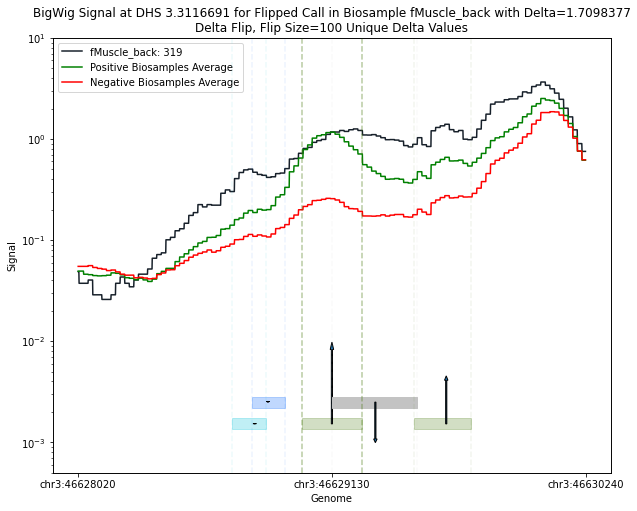

In [215]:
for i in np.argsort(cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas)[:10]:
    plotting_signal_overlapping(i)

In [216]:
#most positive overlapping deltas
np.argsort(-cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas)

array([ 6634, 11971,  7062, ...,  9894,  9871, 22652])

BigWig Signal at DHS 6.658878 for Flipped Call in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


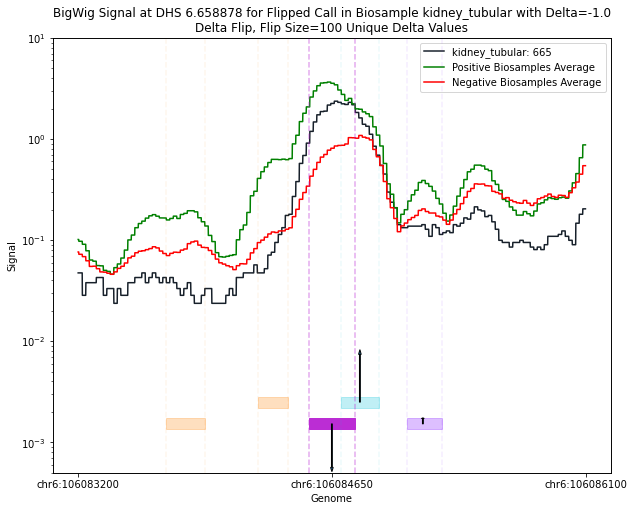

BigWig Signal at DHS 5.480737 for Flipped Call in Biosample HIPEpiC with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


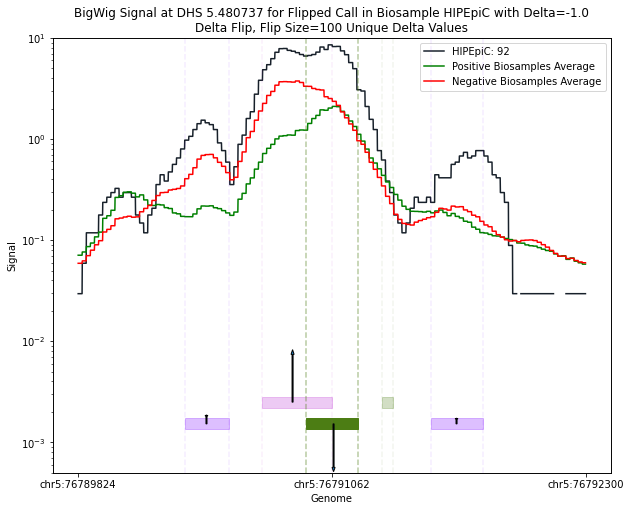

BigWig Signal at DHS 6.2856669 for Flipped Call in Biosample fLeftVentricle with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


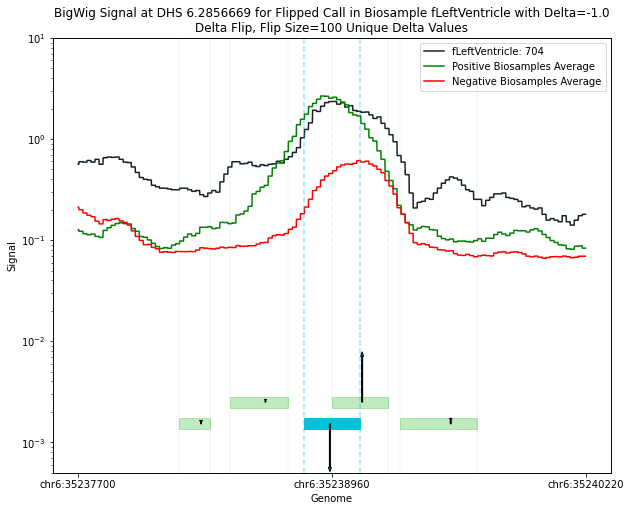

BigWig Signal at DHS 3.589863 for Flipped Call in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


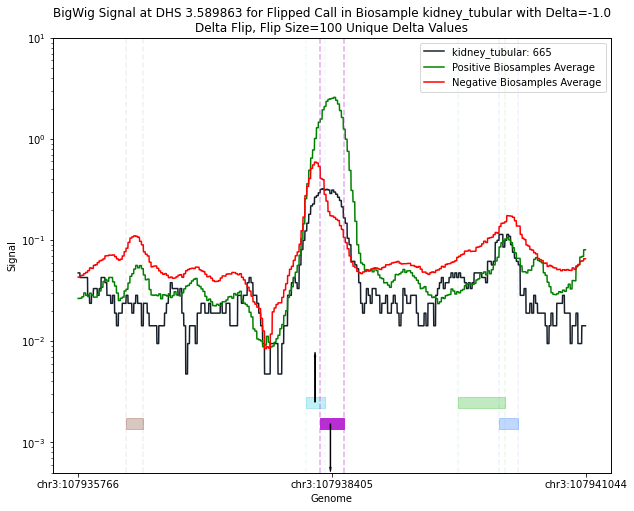

BigWig Signal at DHS 14.777366 for Flipped Call in Biosample NHA with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


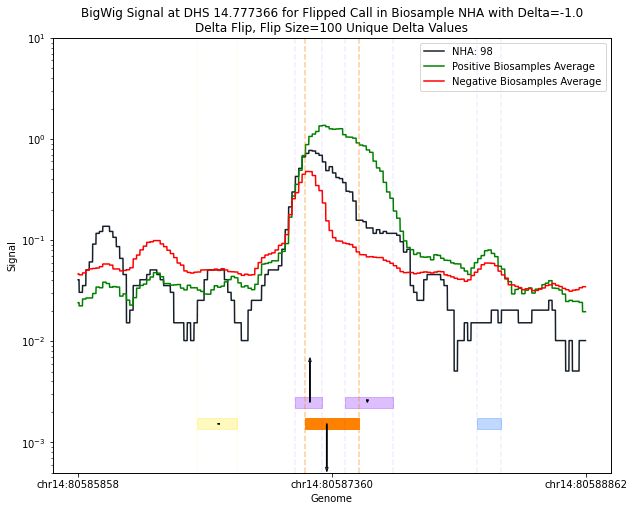

In [217]:
for i in np.argsort(-cycle1_flipped_call_overlapping_polar_opposite_extreme_deltas)[:5]:
    plotting_signal_overlapping(i)

In [213]:
def plotting_signal_overlapping(i, buffer=500):
    #find biosample with call of interest
    biosample = cycle1_flipped_call_biosample_inds[i]
    #dhs of call of interest
    dhs = cycle1_flipped_call_DHS_inds[i]
    #chrm for DHS
    chrm = cycle1_flipped_call_DHS_chr[i]
    #two upstream and two downstream DHSs
#     dhss_inds_to_plot = DHS_inds_with_top_changes_left_to_right[:, i]
    dhss_inds_to_plot = np.arange((dhs-2),(dhs+3))
    for overlapping_dhs in cycle1_flipped_call_overlapping_DHSs[i]:
        if overlapping_dhs not in dhss_inds_to_plot:
            dhss_inds_to_plot = np.append(dhss_inds_to_plot, overlapping_dhs)
            dhss_inds_to_plot = np.sort(dhss_inds_to_plot)
    #presence or absence in original matrix
    dhss_to_plot_original_vals = cycle0_dhs_arr[biosample, dhss_inds_to_plot]
    #delta values of calls
    dhss_to_plot_delta_vals = cycle1_diff_flat[dhss_inds_to_plot + (biosample * n_DHSs)]
    dhs_of_interest_delta_val = cycle1_diff_flat[dhs + (biosample * n_DHSs)]
    #metadata for each DHS
    dhss_to_plot_df = DHS_metadata.loc[dhss_inds_to_plot]
    dhss_to_plot_comps = np.array(dhss_to_plot_df['component'])
    dhss_to_plot_comp_color = []
    for comp in dhss_to_plot_comps:
        comp_ind = np.where(comps==comp)[0]
        dhss_to_plot_comp_color.append(color[comp_ind][0])
    dhs_of_interest_name = np.array(DHS_metadata.loc[dhs]['identifier'])
    
    dhss_to_plot_start = np.array(DHS_metadata.loc[dhss_inds_to_plot]['start'])
    dhss_to_plot_end = np.array(DHS_metadata.loc[dhss_inds_to_plot]['end'])
    dhss_to_plot_summit = np.array(DHS_metadata.loc[dhss_inds_to_plot]['summit'])
    #placing DHS of interest in center
    first_dhs_start = dhss_to_plot_start[0]
    last_dhs_end = dhss_to_plot_end[-1]
    
    dhs_of_interest_start = np.array(DHS_metadata.loc[dhs]['start'])
    dhs_of_interest_end = np.array(DHS_metadata.loc[dhs]['end'])
    
    dhs_of_interest_center = int((dhs_of_interest_start + dhs_of_interest_end)/2)
    max_dhs_dist_to_center = np.max([dhs_of_interest_center - first_dhs_start, last_dhs_end - dhs_of_interest_center])
    start = dhs_of_interest_center - buffer - max_dhs_dist_to_center
    end = dhs_of_interest_center + buffer + max_dhs_dist_to_center

    #load bw file for biosample of interest
    agnum = biosample_df.loc[biosample]['Altius Aggregation ID'][2:]
    lnnum = biosample_df.loc[biosample]['Altius Library ID']
    if lnnum[-1].isalpha():
        lnnum = lnnum[:-1]
    read_in_question_biosample_name = biosample_df.loc[biosample]['Biosample name']
    # print(agnum)
    # print(lnnum)
    filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
    bw_file = pyBigWig.open(filename)
    
    read_in_question = bw_file.values(chrm, 
                                      start, 
                                      end, 
                                      numpy=True)
    
    #finding all biosamples positive for call of interest and removing biosample of interest 
    other_positive_biosamples = np.where(cycle0_dhs_arr[:, dhs]==True)[0]
    other_positive_biosamples = other_positive_biosamples[other_positive_biosamples!=biosample]
    
    #load bw file for all positive biosamples
    base_signal_values = []
    for base_biosample in other_positive_biosamples: 
        agnum = biosample_df.loc[base_biosample]['Altius Aggregation ID'][2:]
        lnnum = biosample_df.loc[base_biosample]['Altius Library ID']
        if lnnum[-1].isalpha():
            lnnum = lnnum[:-1]
#         base_read_biosample_name = biosample_df.loc[base_biosample]['Biosample name']
    #     print(agnum, lnnum)
        filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
        base_read = bw_file.values(chrm, 
                                   start, 
                                   end, 
                                   numpy=True)
        base_signal_values.append(base_read)
    base_signal_values = np.array(base_signal_values)
    #bp average signal
    base_signal_values_ave = np.nanmean(base_signal_values, axis=0)
    
    
    
    
    #finding all biosamples negative for call of interest 
    negative_biosamples = np.where(cycle0_dhs_arr[:, dhs]==False)[0]
    negative_biosamples = negative_biosamples[negative_biosamples!=biosample]
    
    #load bw file for all negative biosamples
    negative_signal_values = []
    for negative_biosample in negative_biosamples: 
        agnum = biosample_df.loc[negative_biosample]['Altius Aggregation ID'][2:]
        lnnum = biosample_df.loc[negative_biosample]['Altius Library ID']
        if lnnum[-1].isalpha():
            lnnum = lnnum[:-1]
#         negative_read_biosample_name = biosample_df.loc[negative_biosample]['Biosample name']
    #     print(agnum, lnnum)
        filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
        negative_read = bw_file.values(chrm, 
                                       start, 
                                       end, 
                                       numpy=True)
        negative_signal_values.append(negative_read)
    negative_signal_values = np.array(negative_signal_values)
    #bp average signal
    negative_signal_values_ave = np.nanmean(negative_signal_values, axis=0)
    
    
    
    #plotting
    fig, ax1 = plt.subplots(figsize=(10,8))
#     fig = plt.figure(figsize=(10,8))
    fig.patch.set_facecolor('white')

    ax1.plot(np.arange(start, end), read_in_question, color='#17202A')
    ax1.plot(np.arange(start, end), base_signal_values_ave, color='g')
    ax1.plot(np.arange(start, end), negative_signal_values_ave, color='r')
    
    ax2 = ax1.twinx()
    
    for ind in range(len(dhss_inds_to_plot)):
        if ind == 2:
            a=0.4
        else:
            a=0.075
        ax2.plot([dhss_to_plot_start[ind], dhss_to_plot_start[ind]], [0, 1], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
        ax2.plot([dhss_to_plot_end[ind], dhss_to_plot_end[ind]], [0, 1], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
        
        min_rect_base = 0.1
        if ind % 2 == 0:
            rect_base = min_rect_base
        else:
            rect_base = min_rect_base + 0.05
        if dhss_to_plot_original_vals[ind]:
            a = 1
        else:
            a = 0.25
#         plt.plot(np.arange(dhss_to_plot_start[ind], dhss_to_plot_end[ind]), np.zeros(dhss_to_plot_end[ind] - dhss_to_plot_start[ind])+line_height, color=dhss_to_plot_comp_color[ind])
        dhs_rect = patches.Rectangle((dhss_to_plot_start[ind], rect_base),
                                     dhss_to_plot_end[ind] - dhss_to_plot_start[ind], 
                                     0.025,
                                     alpha=a,
                                     color = dhss_to_plot_comp_color[ind])
        fig.gca().add_patch(dhs_rect)
        
        

        arrow_base = rect_base + 0.0125
            
        ax2.arrow(dhss_to_plot_summit[ind], 
                  arrow_base, 
                  0, 
                  dhss_to_plot_delta_vals[ind]/10, 
                  width=5, 
                  length_includes_head=False,
                  head_length=np.abs(dhss_to_plot_delta_vals[ind]/100))
        

        
    
    ax1.set_xticks([start, int((end+start)/2), end])
    ax1.set_xticklabels([chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])

    ax1.legend([read_in_question_biosample_name + ': ' + str(biosample), 
                'Positive Biosamples Average',
                'Negative Biosamples Average'])
    ax1.set_yscale('log')
    ax1.set_xlabel('Genome')
    ax1.set_ylabel('Signal')
    ax1.set_ylim([0.0005, 10])
    ax2.set_ylim([0, 1])
    ax2.set_yticks([])
    plot_title = 'BigWig Signal at DHS %s for Flipped Call in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhs_of_interest_name, read_in_question_biosample_name, dhs_of_interest_delta_val)
    print(plot_title)
    plt.title(plot_title)
    plt.show()

**Fraction of flipped peaks that have delta value of opposite polarity in neighboring DHS**

In [199]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
cycle1_diff_flat = cycle_np_file['diff_flat_array']

In [13]:
#finding flat inds of neighboring DHSs to changed calls
cycle1_flipped_call_flat_inds = np.append(added_flat_inds_all_cycles[0], removed_flat_inds_all_cycles[0])
cycle1_flipped_call_flat_inds_1right = cycle1_flipped_call_flat_inds + 1
cycle1_flipped_call_flat_inds_2right = cycle1_flipped_call_flat_inds + 2
cycle1_flipped_call_flat_inds_1left = cycle1_flipped_call_flat_inds - 1
cycle1_flipped_call_flat_inds_2left = cycle1_flipped_call_flat_inds - 2

#finding delta vals for center DHS and neighbors
cycle1_flipped_call_flat_inds_left_to_right = np.array([cycle1_flipped_call_flat_inds_2left, 
                                                      cycle1_flipped_call_flat_inds_1left, 
                                                      cycle1_flipped_call_flat_inds,
                                                      cycle1_flipped_call_flat_inds_1right, 
                                                      cycle1_flipped_call_flat_inds_2right])
cycle1_flipped_call_delta_left_to_right = cycle1_diff_flat[cycle1_flipped_call_flat_inds_left_to_right]

In [14]:
#finding where center DHS and neighboring DHSs have opposite polarity in delta values
neg_thresh = -0.5
pos_thresh = 0.5
# cycle1_centerpos_neighborneg = ((cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[0] < neg_thresh) | 
#                                (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[1] < neg_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[3] < neg_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[4] < neg_thresh))

# cycle1_centerneg_neighborpos = ((cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[0] > pos_thresh) | 
#                                (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[1] > pos_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[3] > pos_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[4] > pos_thresh))

cycle1_centerpos_neighborneg = ((cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[1] < neg_thresh) |
                               (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[3] < neg_thresh))

cycle1_centerneg_neighborpos = ((cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[1] > pos_thresh) |
                               (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[3] > pos_thresh))

#inds relative to cycle1_flipped_call_flat_inds
cycle1_centerpos_neighborneg_inds = np.arange(len(cycle1_centerpos_neighborneg))[cycle1_centerpos_neighborneg]
cycle1_centerneg_neighborpos_inds = np.arange(len(cycle1_centerneg_neighborpos))[cycle1_centerneg_neighborpos]

print(np.sum(cycle1_centerpos_neighborneg.astype(int) + cycle1_centerneg_neighborpos.astype(int)))
print(np.sum(cycle1_centerpos_neighborneg.astype(int) + cycle1_centerneg_neighborpos.astype(int)) / len(cycle1_flipped_call_delta_left_to_right[2]))
print(np.sum(cycle1_centerpos_neighborneg.astype(int)))
print(np.sum(cycle1_centerneg_neighborpos.astype(int)))

207
0.009137862534763607
37
170


In [12]:
#simulation to see how many randomly draw delta values acting as neighbors to flipped calls 
#are above/below some threshold 
count_list = []
for j in range(10):
    count = 0
    for i in range(len(cycle1_flipped_call_flat_inds)):
        ind1 = random.randrange(0, len(cycle1_diff_flat))
        ind2 = random.randrange(0, len(cycle1_diff_flat))
        while ind1==ind2:
            ind2 = random.randrange(0, len(cycle1_diff_flat))
        if ((i < 100) & ((cycle1_diff_flat[ind1] < -0.5) | (cycle1_diff_flat[ind2] < -0.5))):
            count += 1
        elif ((i >= 100) & ((cycle1_diff_flat[ind1] > 0.5) | (cycle1_diff_flat[ind2] > 0.5))):
            count += 1
    count_list.append(count)
print(np.mean(count_list))
print(len(cycle1_flipped_call_flat_inds))

132.2
22653


In [207]:
localinds_with_top_changes = np.append(cycle1_centerpos_neighborneg_inds, cycle1_centerneg_neighborpos_inds)
flat_inds_with_top_changes_left_to_right = cycle1_flipped_call_flat_inds_left_to_right[:, localinds_with_top_changes]

In [208]:
DHS_inds_with_top_changes_left_to_right = flat_inds_with_top_changes_left_to_right % n_DHSs
biosample_inds_with_top_changes_left_to_right = flat_inds_with_top_changes_left_to_right // n_DHSs

DHS_chr_with_top_changes = np.array(DHS_metadata.loc[DHS_inds_with_top_changes_left_to_right[2, :]]['seqname'])
DHS_start_with_top_changes = np.array(DHS_metadata.loc[DHS_inds_with_top_changes_left_to_right[2, :]]['start'])
DHS_end_with_top_changes = np.array(DHS_metadata.loc[DHS_inds_with_top_changes_left_to_right[2, :]]['end'])

BigWig Signal at DHS 10.409564 for Flipped Call in Biosample Small_Intestine_Mucosa with Delta=1.6420196
Delta Flip, Flip Size=100 Unique Delta Values


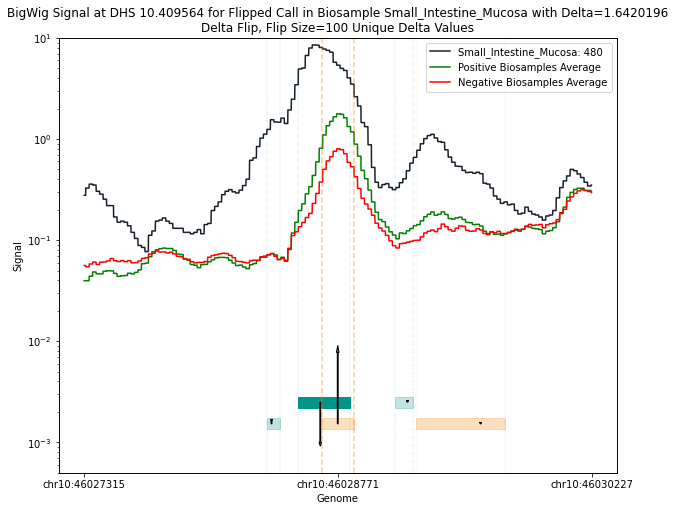

BigWig Signal at DHS 8.925174 for Flipped Call in Biosample fMuscle_trunk with Delta=1.6311772
Delta Flip, Flip Size=100 Unique Delta Values


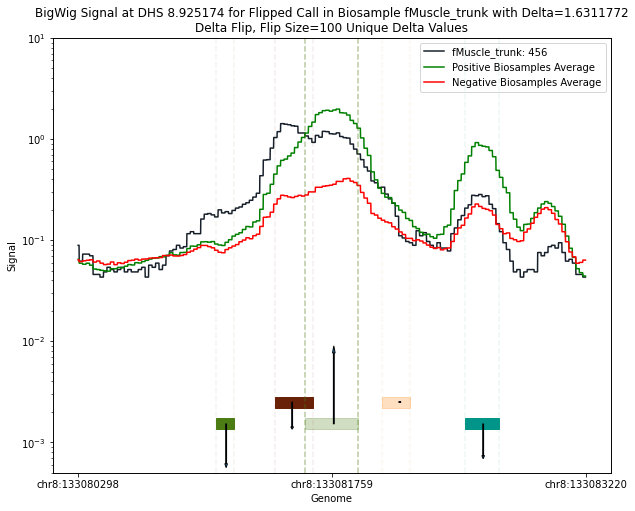

BigWig Signal at DHS 6.898888 for Flipped Call in Biosample hESCT0 with Delta=1.5508898
Delta Flip, Flip Size=100 Unique Delta Values


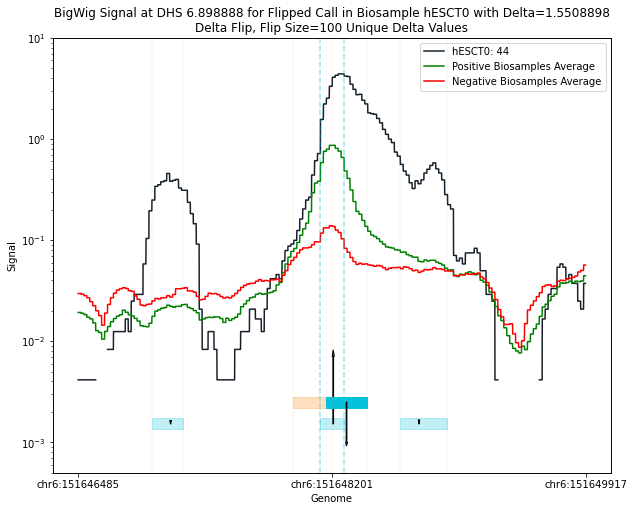

BigWig Signal at DHS 1.8964466 for Flipped Call in Biosample fKidney with Delta=1.5458661
Delta Flip, Flip Size=100 Unique Delta Values


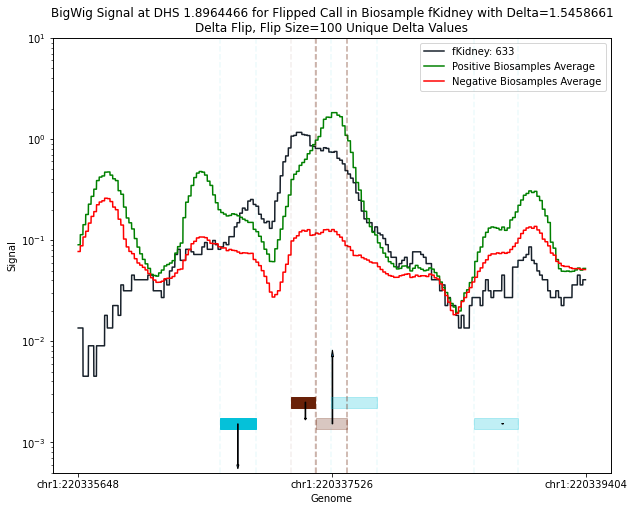

BigWig Signal at DHS 2.5206476 for Flipped Call in Biosample fIntestine_Lg with Delta=1.501233
Delta Flip, Flip Size=100 Unique Delta Values


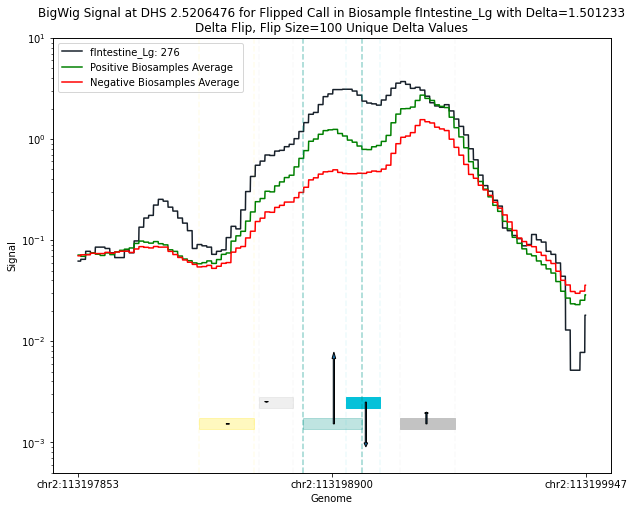

BigWig Signal at DHS 12.907887 for Flipped Call in Biosample Mesendoderm with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


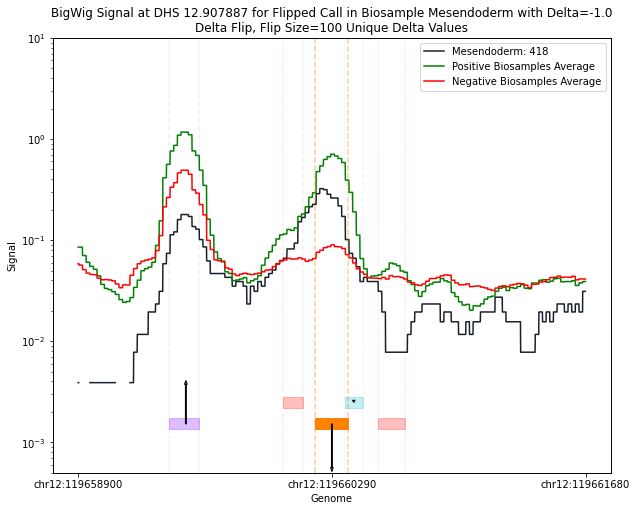

BigWig Signal at DHS 17.554227 for Flipped Call in Biosample fKidney_L with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


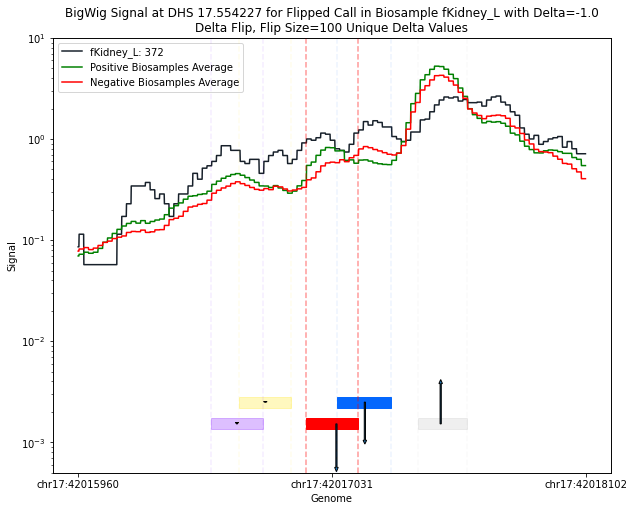

BigWig Signal at DHS 3.589863 for Flipped Call in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


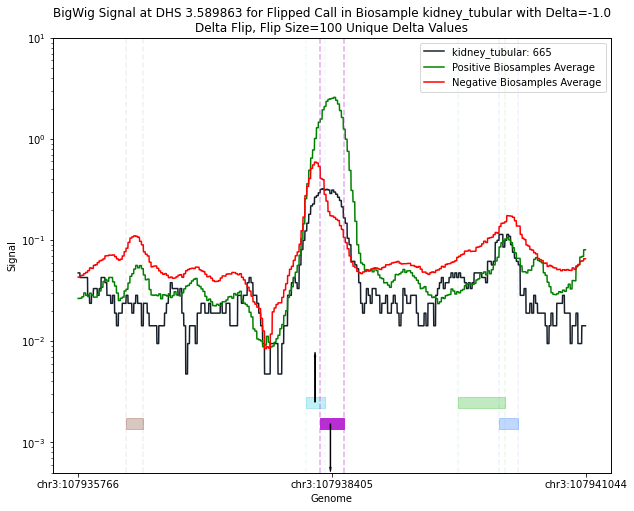

BigWig Signal at DHS 22.693016 for Flipped Call in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


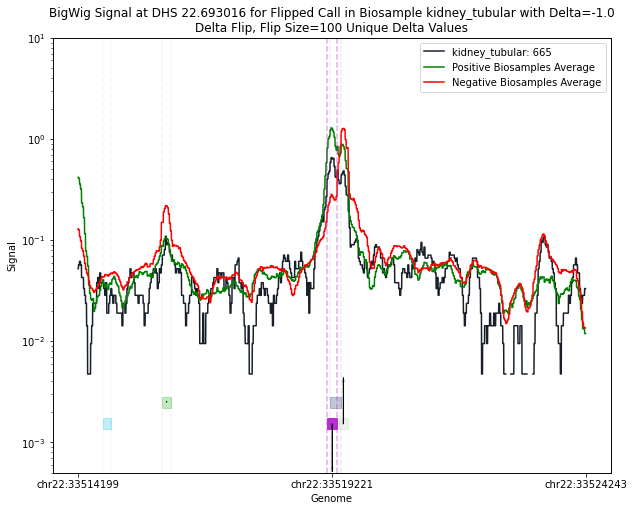

BigWig Signal at DHS 22.57432 for Flipped Call in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


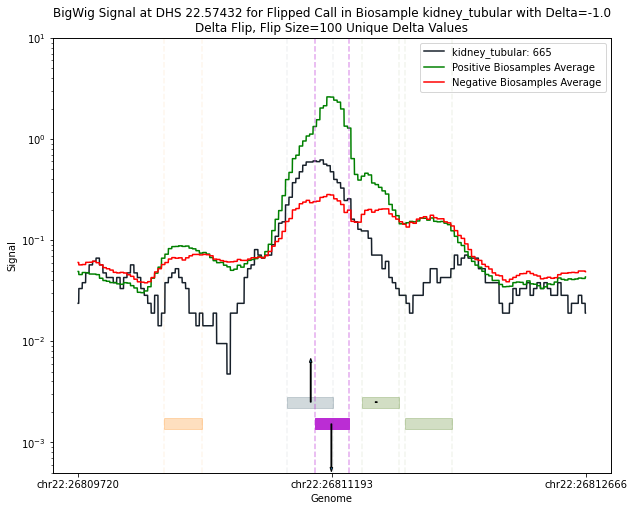

BigWig Signal at DHS 6.658878 for Flipped Call in Biosample kidney_tubular with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


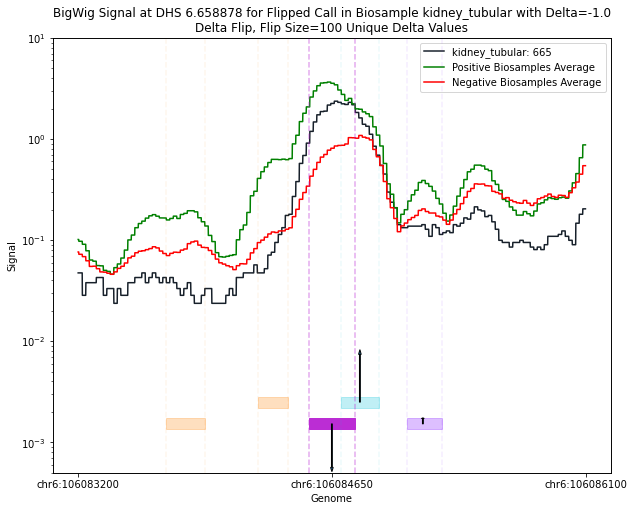

BigWig Signal at DHS 6.2856669 for Flipped Call in Biosample fLeftVentricle with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


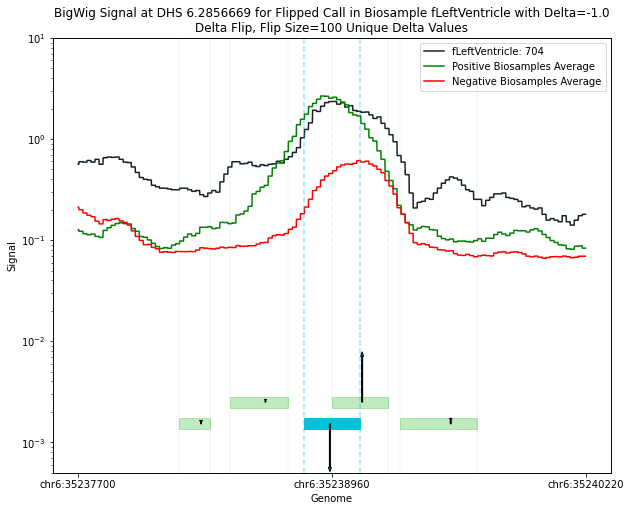

BigWig Signal at DHS 18.392163 for Flipped Call in Biosample DE with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


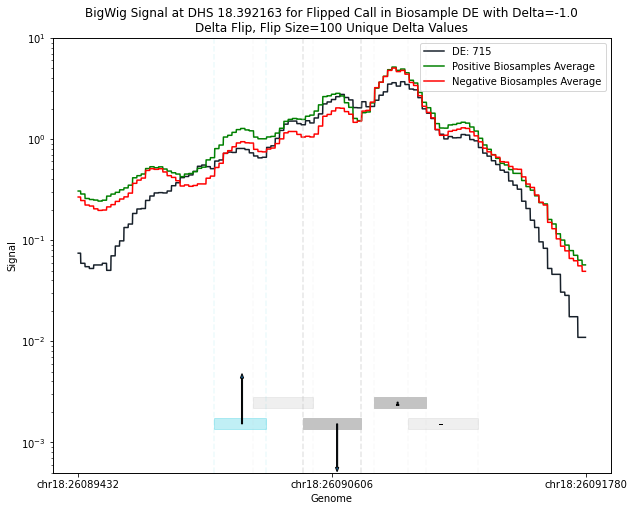

BigWig Signal at DHS 6.849713 for Flipped Call in Biosample DE with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


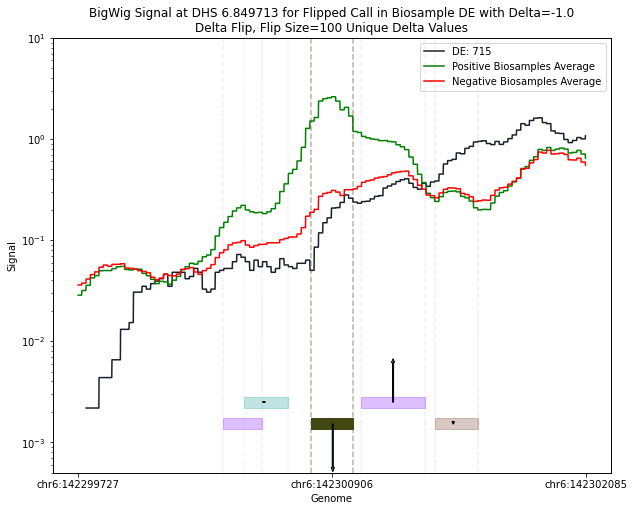

BigWig Signal at DHS 14.777366 for Flipped Call in Biosample NHA with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


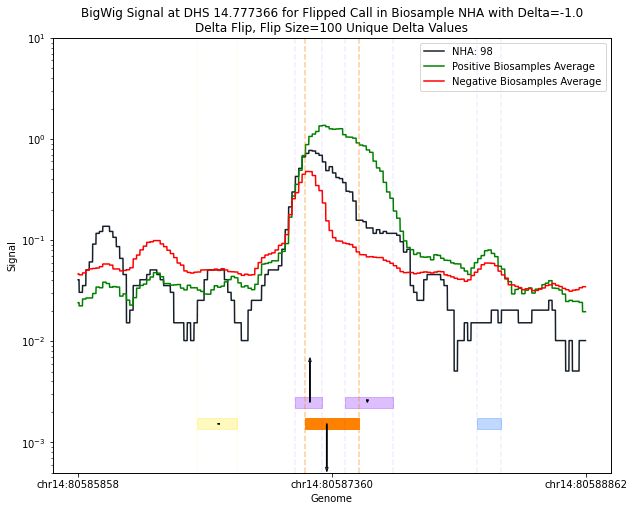

BigWig Signal at DHS 5.480737 for Flipped Call in Biosample HIPEpiC with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


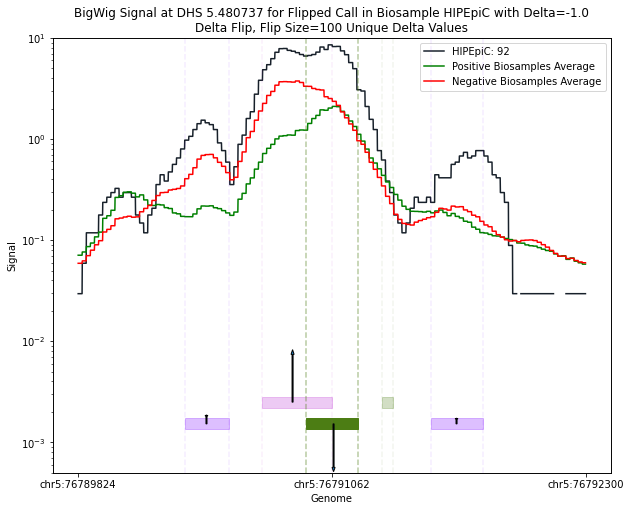

BigWig Signal at DHS 12.5226932 for Flipped Call in Biosample SAEC with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


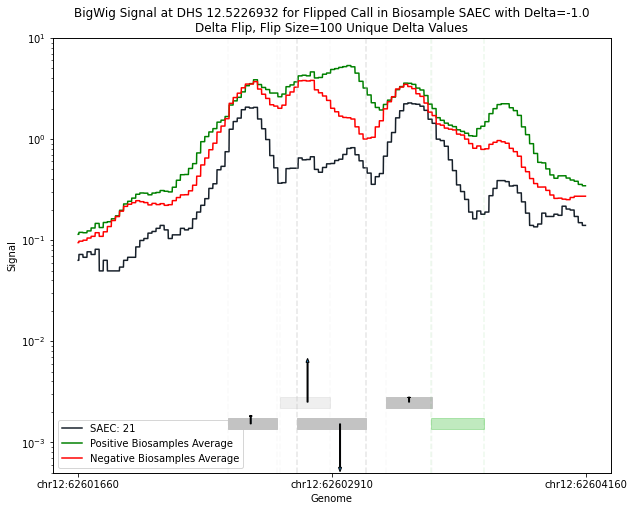

BigWig Signal at DHS 2.4174564 for Flipped Call in Biosample fBrain with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


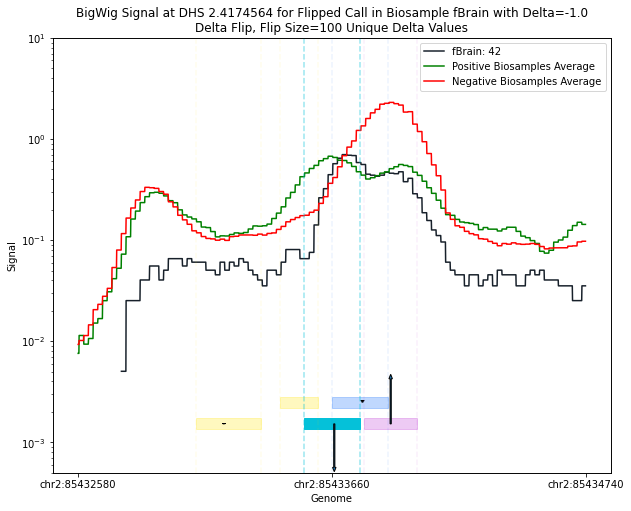

BigWig Signal at DHS 1.5020495 for Flipped Call in Biosample CD56 with Delta=-1.0
Delta Flip, Flip Size=100 Unique Delta Values


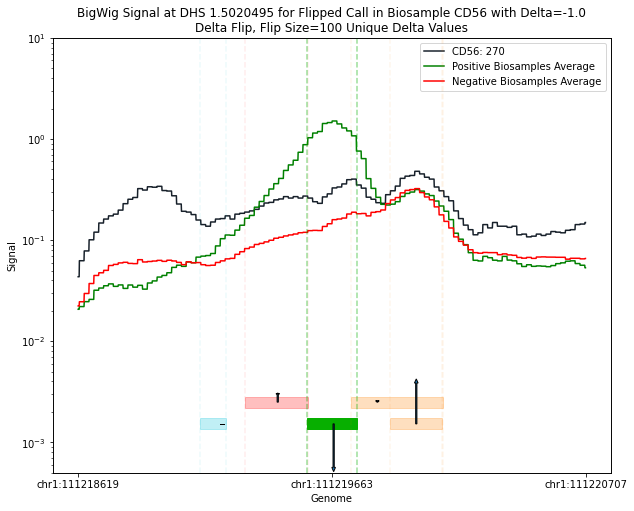

In [212]:
#all from threshold values of 0.9 and -0.9
for i in range(19):
    plotting_signal_top_changes(i)

In [211]:
def plotting_signal_top_changes(i, buffer=500):
    #find biosample with call of interest
    biosample = biosample_inds_with_top_changes_left_to_right[2, i]
    #dhs of call of interest
    dhs = DHS_inds_with_top_changes_left_to_right[2, i]
    #chrm for DHS
    chrm = DHS_chr_with_top_changes[i]
    #two upstream and two downstream DHSs
    dhss_inds_to_plot = DHS_inds_with_top_changes_left_to_right[:, i]
    #presence or absence in original matrix
    dhss_to_plot_original_vals = cycle0_dhs_arr[biosample, dhss_inds_to_plot]
    #delta values of calls
    dhss_to_plot_delta_vals = cycle1_diff_flat[dhss_inds_to_plot + (biosample * n_DHSs)]
    #metadata for each DHS
    dhss_to_plot_df = DHS_metadata.loc[dhss_inds_to_plot]
    dhss_to_plot_comps = np.array(dhss_to_plot_df['component'])
    dhss_to_plot_comp_color = []
    for comp in dhss_to_plot_comps:
        comp_ind = np.where(comps==comp)[0]
        dhss_to_plot_comp_color.append(color[comp_ind][0])
    dhss_to_plot_names = np.array(DHS_metadata.loc[dhss_inds_to_plot]['identifier'])
    dhss_to_plot_start = np.array(DHS_metadata.loc[dhss_inds_to_plot]['start'])
    dhss_to_plot_end = np.array(DHS_metadata.loc[dhss_inds_to_plot]['end'])
    dhss_to_plot_summit = np.array(DHS_metadata.loc[dhss_inds_to_plot]['summit'])
    #placing DHS of interest in center
    first_dhs_start = dhss_to_plot_start[0]
    last_dhs_end = dhss_to_plot_end[-1]
    dhs_of_interest_center = int((dhss_to_plot_start[2] + dhss_to_plot_end[2])/2)
    max_dhs_dist_to_center = np.max([dhs_of_interest_center - first_dhs_start, last_dhs_end - dhs_of_interest_center])
    start = dhs_of_interest_center - buffer - max_dhs_dist_to_center
    end = dhs_of_interest_center + buffer + max_dhs_dist_to_center

    #load bw file for biosample of interest
    agnum = biosample_df.loc[biosample]['Altius Aggregation ID'][2:]
    lnnum = biosample_df.loc[biosample]['Altius Library ID']
    if lnnum[-1].isalpha():
        lnnum = lnnum[:-1]
    read_in_question_biosample_name = biosample_df.loc[biosample]['Biosample name']
    # print(agnum)
    # print(lnnum)
    filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
    bw_file = pyBigWig.open(filename)
    read_in_question = bw_file.values(chrm, 
                                      start, 
                                      end, 
                                      numpy=True)
    
    #finding all biosamples positive for call of interest and removing biosample of interest 
    other_positive_biosamples = np.where(cycle0_dhs_arr[:, dhs]==True)[0]
    other_positive_biosamples = other_positive_biosamples[other_positive_biosamples!=biosample]
    
    #load bw file for all positive biosamples
    base_signal_values = []
    for base_biosample in other_positive_biosamples: 
        agnum = biosample_df.loc[base_biosample]['Altius Aggregation ID'][2:]
        lnnum = biosample_df.loc[base_biosample]['Altius Library ID']
        if lnnum[-1].isalpha():
            lnnum = lnnum[:-1]
#         base_read_biosample_name = biosample_df.loc[base_biosample]['Biosample name']
    #     print(agnum, lnnum)
        filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
        base_read = bw_file.values(chrm, 
                                   start, 
                                   end, 
                                   numpy=True)
        base_signal_values.append(base_read)
    base_signal_values = np.array(base_signal_values)
    #bp average signal
    base_signal_values_ave = np.nanmean(base_signal_values, axis=0)
    
    
    
    
    #finding all biosamples negative for call of interest 
    negative_biosamples = np.where(cycle0_dhs_arr[:, dhs]==False)[0]
    negative_biosamples = negative_biosamples[negative_biosamples!=biosample]
    
    #load bw file for all negative biosamples
    negative_signal_values = []
    for negative_biosample in negative_biosamples: 
        agnum = biosample_df.loc[negative_biosample]['Altius Aggregation ID'][2:]
        lnnum = biosample_df.loc[negative_biosample]['Altius Library ID']
        if lnnum[-1].isalpha():
            lnnum = lnnum[:-1]
#         negative_read_biosample_name = biosample_df.loc[negative_biosample]['Biosample name']
    #     print(agnum, lnnum)
        filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
        negative_read = bw_file.values(chrm, 
                                       start, 
                                       end, 
                                       numpy=True)
        negative_signal_values.append(negative_read)
    negative_signal_values = np.array(negative_signal_values)
    #bp average signal
    negative_signal_values_ave = np.nanmean(negative_signal_values, axis=0)
    
    
    
    #plotting
    fig, ax1 = plt.subplots(figsize=(10,8))
#     fig = plt.figure(figsize=(10,8))
    fig.patch.set_facecolor('white')

    ax1.plot(np.arange(start, end), read_in_question, color='#17202A')
    ax1.plot(np.arange(start, end), base_signal_values_ave, color='g')
    ax1.plot(np.arange(start, end), negative_signal_values_ave, color='r')
    
    ax2 = ax1.twinx()
    
    for ind in range(5):
        if ind == 2:
            a=0.4
        else:
            a=0.075
        ax2.plot([dhss_to_plot_start[ind], dhss_to_plot_start[ind]], [0, 1], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
        ax2.plot([dhss_to_plot_end[ind], dhss_to_plot_end[ind]], [0, 1], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
        
        min_rect_base = 0.1
        if ind % 2 == 0:
            rect_base = min_rect_base
        else:
            rect_base = min_rect_base + 0.05
        if dhss_to_plot_original_vals[ind]:
            a = 1
        else:
            a = 0.25
#         plt.plot(np.arange(dhss_to_plot_start[ind], dhss_to_plot_end[ind]), np.zeros(dhss_to_plot_end[ind] - dhss_to_plot_start[ind])+line_height, color=dhss_to_plot_comp_color[ind])
        dhs_rect = patches.Rectangle((dhss_to_plot_start[ind], rect_base),
                                     dhss_to_plot_end[ind] - dhss_to_plot_start[ind], 
                                     0.025,
                                     alpha=a,
                                     color = dhss_to_plot_comp_color[ind])
        fig.gca().add_patch(dhs_rect)
        
        

        arrow_base = rect_base + 0.0125
            
        ax2.arrow(dhss_to_plot_summit[ind], 
                  arrow_base, 
                  0, 
                  dhss_to_plot_delta_vals[ind]/10, 
                  width=5, 
                  length_includes_head=False,
                  head_length=np.abs(dhss_to_plot_delta_vals[ind]/100))
        

        
    
    ax1.set_xticks([start, int((end+start)/2), end])
    ax1.set_xticklabels([chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])

    ax1.legend([read_in_question_biosample_name + ': ' + str(biosample), 
                'Positive Biosamples Average',
                'Negative Biosamples Average'])
    ax1.set_yscale('log')
    ax1.set_xlabel('Genome')
    ax1.set_ylabel('Signal')
    ax1.set_ylim([0.0005, 10])
    ax2.set_ylim([0, 1])
    ax2.set_yticks([])
    plot_title = 'BigWig Signal at DHS %s for Flipped Call in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhss_to_plot_names[2], read_in_question_biosample_name, dhss_to_plot_delta_vals[2])
    print(plot_title)
    plt.title(plot_title)
    plt.show()

**Seeing if there examples of good removals in top peak signal removed calls**

In [7]:
#finding peak signal values of removed calls
removed_peak_signal_all_cycles = []
for i in range(10):
    print(i)
    removed_peak_signal_single_cycle = []
    for biosample, dhs in zip((removed_flat_inds_all_cycles[i] // n_DHSs), (removed_flat_inds_all_cycles[i] % n_DHSs)):
        removed_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    removed_peak_signal_single_cycle = np.array(removed_peak_signal_single_cycle)
    removed_peak_signal_all_cycles.append(removed_peak_signal_single_cycle)

0
1
2
3
4
5
6
7
8
9


In [8]:
#looking into the top peak signal -1 removed calls
top_100_peak_scores = np.flip(np.sort(removed_peak_signal_all_cycles[0])[-100:])

top_100_neg1_peak_signal_flat_inds = removed_flat_inds_all_cycles[0][np.argsort(-removed_peak_signal_all_cycles[0])[:100]]
top_100_neg1_peak_signal_DHS_inds = top_100_neg1_peak_signal_flat_inds % n_DHSs
top_100_neg1_peak_signal_biosample_inds = top_100_neg1_peak_signal_flat_inds // n_DHSs
top_100_neg1_peak_signal_biosamples = np.array(biosample_df.loc[top_100_neg1_peak_signal_biosample_inds]['Biosample name'])

top_100_neg1_peak_signal_chr = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['seqname'])
top_100_neg1_peak_signal_start = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['start'])
top_100_neg1_peak_signal_end = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['end'])

In [16]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(top_100_neg1_peak_signal_chr[i]) + '\t' + str(top_100_neg1_peak_signal_start[i]) + '\t' + str(top_100_neg1_peak_signal_end[i]) + '\t' + str(top_100_peak_scores[i]) + ' ' + str(top_100_neg1_peak_signal_biosamples[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT20220304.bed


In [11]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
diff_flat = cycle_np_file['diff_flat_array']

1) BigWig Signal at DHS 3.25471 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=104.294
Delta Flip, Flip Size=100 Unique Delta Values


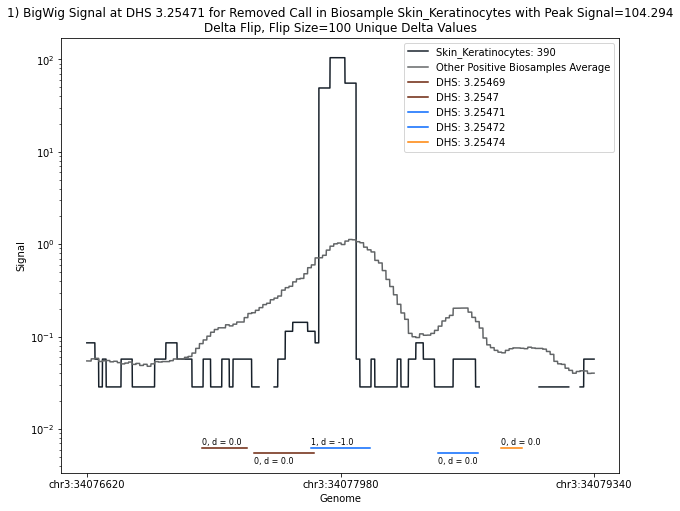

2) BigWig Signal at DHS 5.8642621 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=76.7927
Delta Flip, Flip Size=100 Unique Delta Values


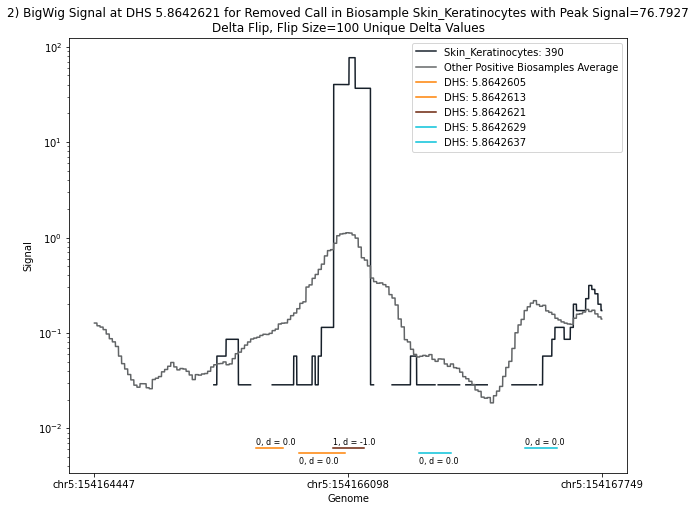

3) BigWig Signal at DHS 6.2045652 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=29.3577
Delta Flip, Flip Size=100 Unique Delta Values


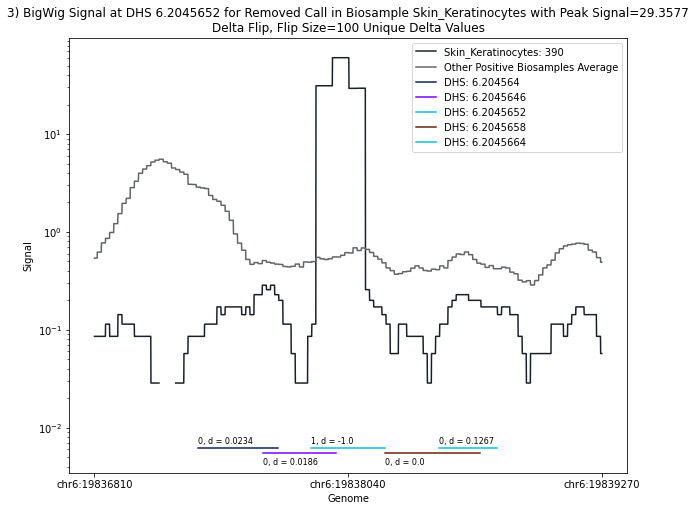

4) BigWig Signal at DHS 2.962169 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=12.0515
Delta Flip, Flip Size=100 Unique Delta Values


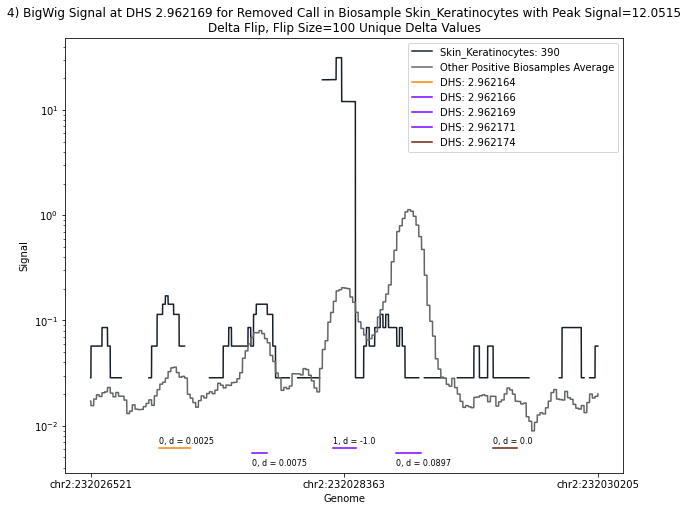

5) BigWig Signal at DHS 11.656873 for Removed Call in Biosample Hela with Peak Signal=11.7659
Delta Flip, Flip Size=100 Unique Delta Values


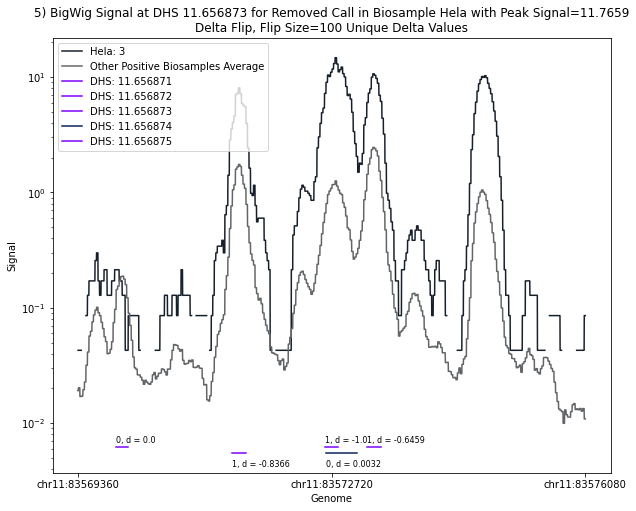

6) BigWig Signal at DHS 22.505828 for Removed Call in Biosample GM06990 with Peak Signal=11.375
Delta Flip, Flip Size=100 Unique Delta Values


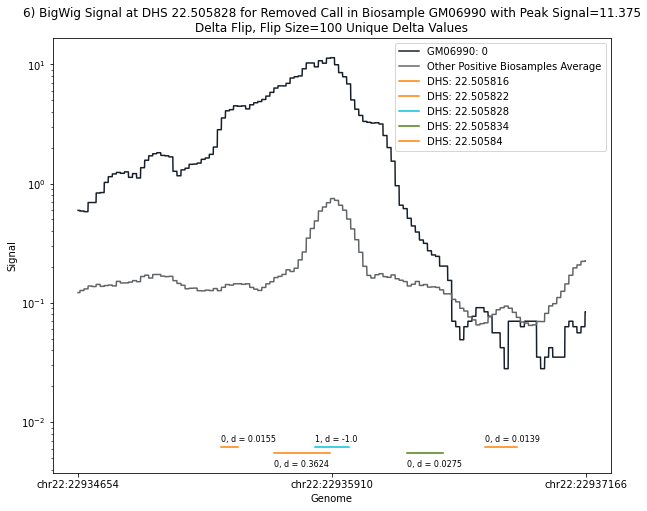

7) BigWig Signal at DHS 19.748262 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=10.6954
Delta Flip, Flip Size=100 Unique Delta Values


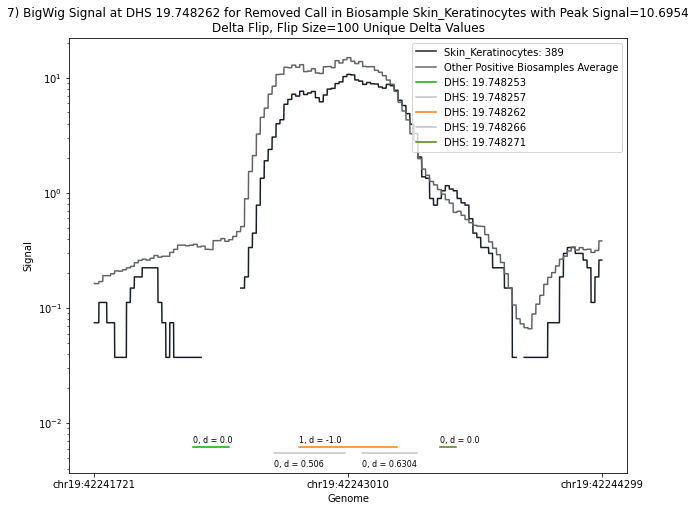

8) BigWig Signal at DHS 19.716286 for Removed Call in Biosample PANC1 with Peak Signal=9.58925
Delta Flip, Flip Size=100 Unique Delta Values


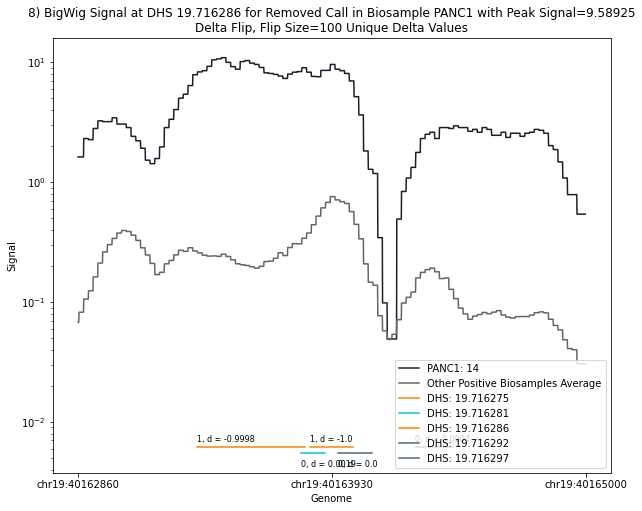

9) BigWig Signal at DHS 8.399226 for Removed Call in Biosample LNCap with Peak Signal=9.44852
Delta Flip, Flip Size=100 Unique Delta Values


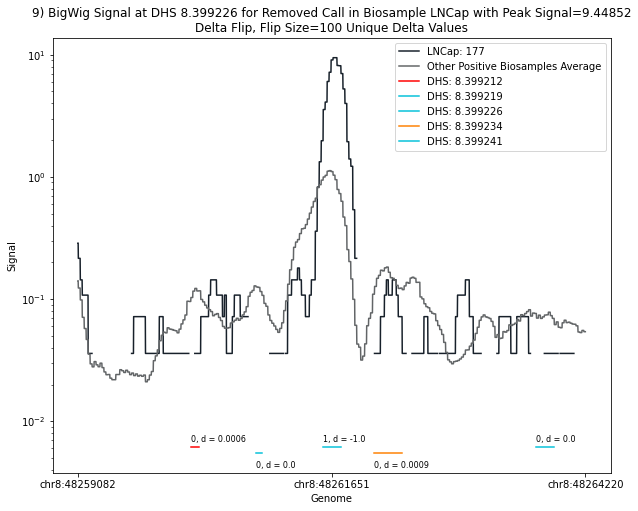

10) BigWig Signal at DHS 3.198976 for Removed Call in Biosample LNCap with Peak Signal=9.05334
Delta Flip, Flip Size=100 Unique Delta Values


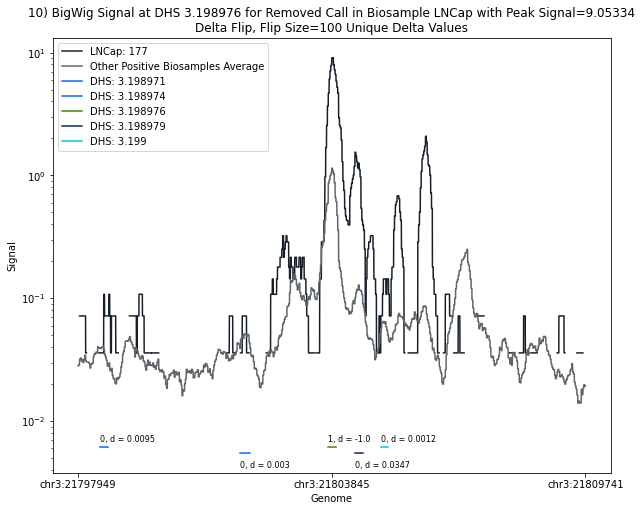

11) BigWig Signal at DHS 13.90778 for Removed Call in Biosample WERI_Rb1 with Peak Signal=8.97441
Delta Flip, Flip Size=100 Unique Delta Values


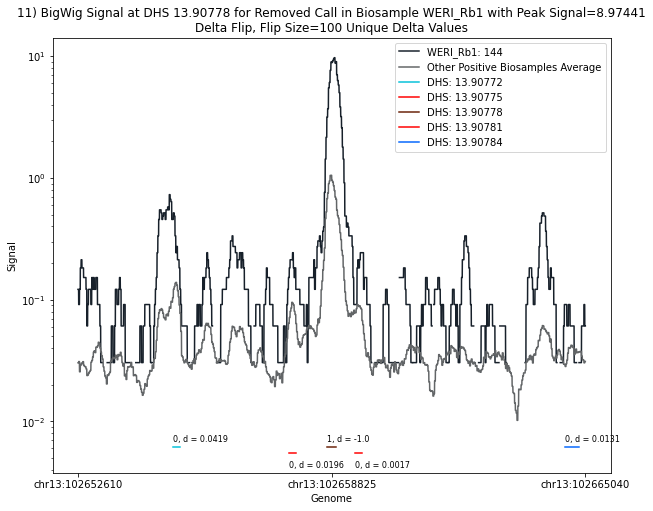

12) BigWig Signal at DHS 15.692292 for Removed Call in Biosample HRE with Peak Signal=8.59358
Delta Flip, Flip Size=100 Unique Delta Values


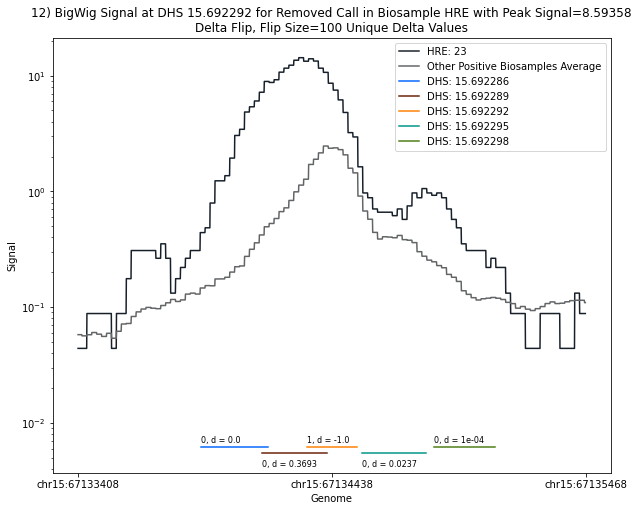

13) BigWig Signal at DHS 2.866872 for Removed Call in Biosample LHCN_M2 with Peak Signal=8.28356
Delta Flip, Flip Size=100 Unique Delta Values


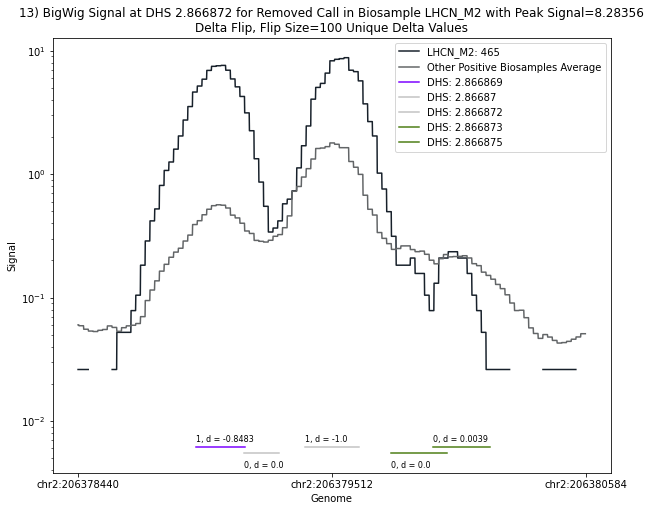

14) BigWig Signal at DHS 5.480737 for Removed Call in Biosample HIPEpiC with Peak Signal=8.21395
Delta Flip, Flip Size=100 Unique Delta Values


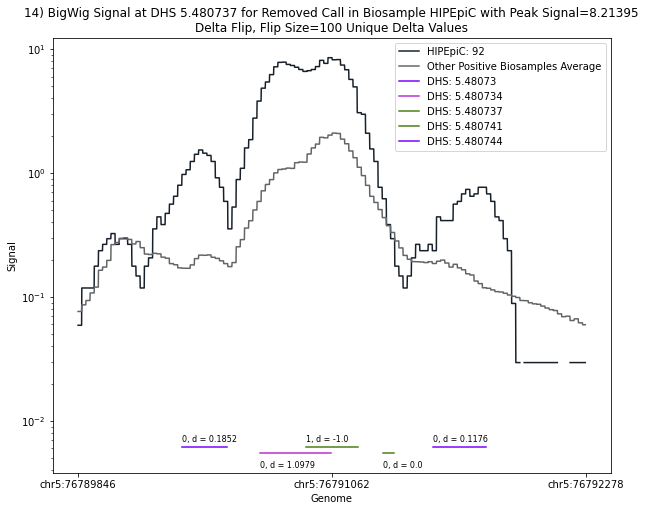

15) BigWig Signal at DHS 15.692292 for Removed Call in Biosample HRE with Peak Signal=8.20305
Delta Flip, Flip Size=100 Unique Delta Values


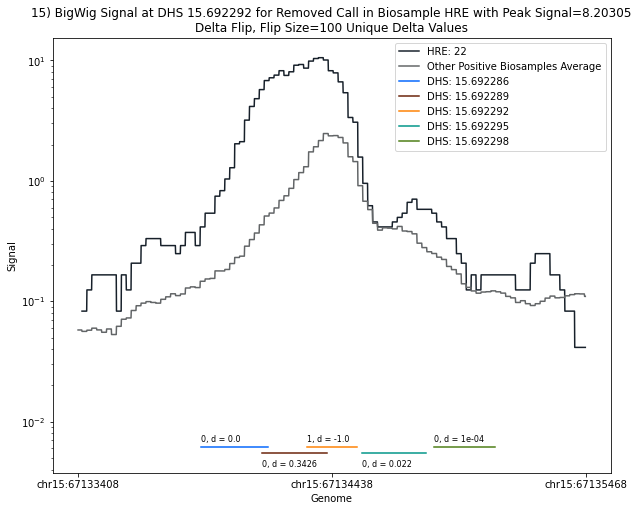

16) BigWig Signal at DHS 8.285177 for Removed Call in Biosample Hela with Peak Signal=8.08636
Delta Flip, Flip Size=100 Unique Delta Values


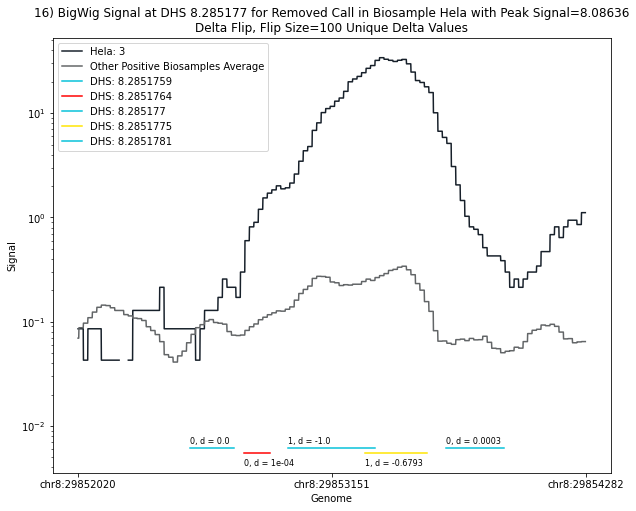

17) BigWig Signal at DHS 1.311706 for Removed Call in Biosample HMEC with Peak Signal=7.97271
Delta Flip, Flip Size=100 Unique Delta Values


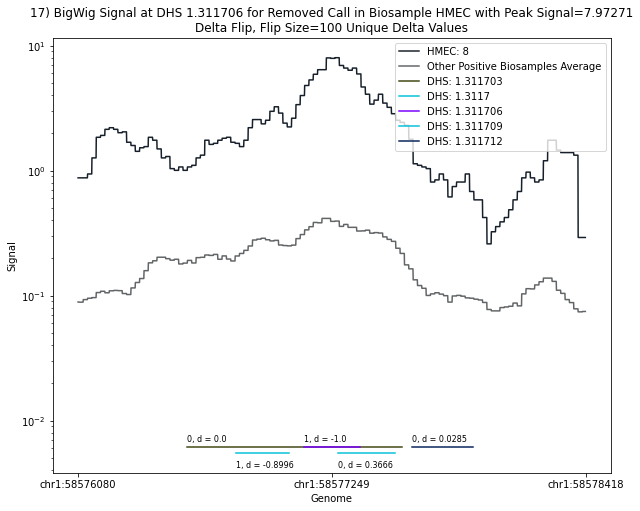

18) BigWig Signal at DHS 1.6490676 for Removed Call in Biosample LNCap with Peak Signal=7.90371
Delta Flip, Flip Size=100 Unique Delta Values


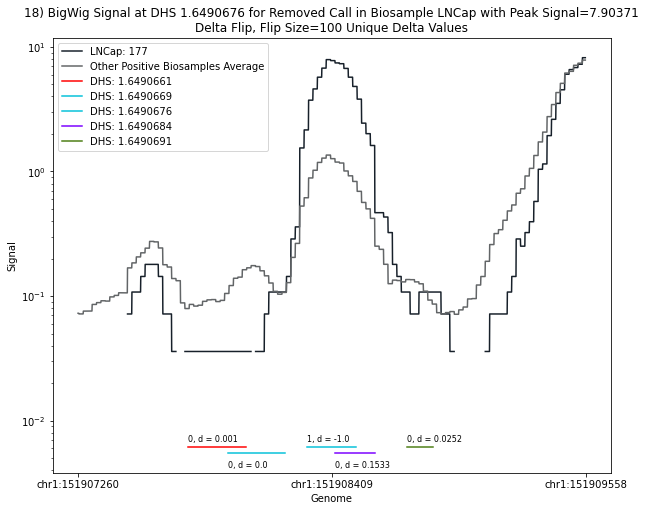

19) BigWig Signal at DHS 15.494661 for Removed Call in Biosample fStomach with Peak Signal=7.88248
Delta Flip, Flip Size=100 Unique Delta Values


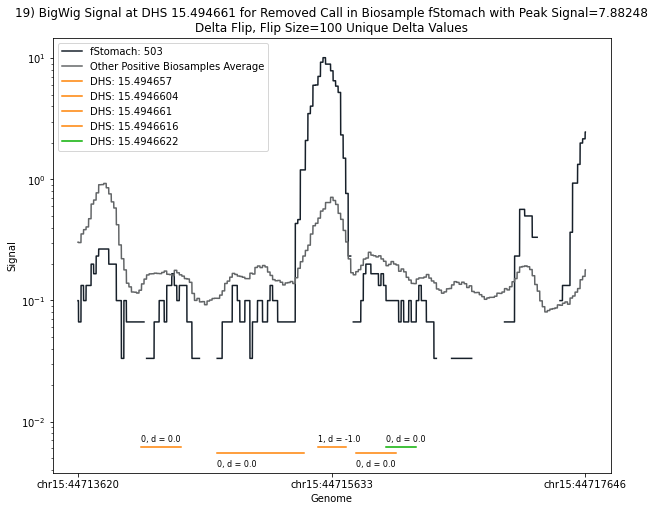

20) BigWig Signal at DHS 2.170737 for Removed Call in Biosample HT29 with Peak Signal=7.82996
Delta Flip, Flip Size=100 Unique Delta Values


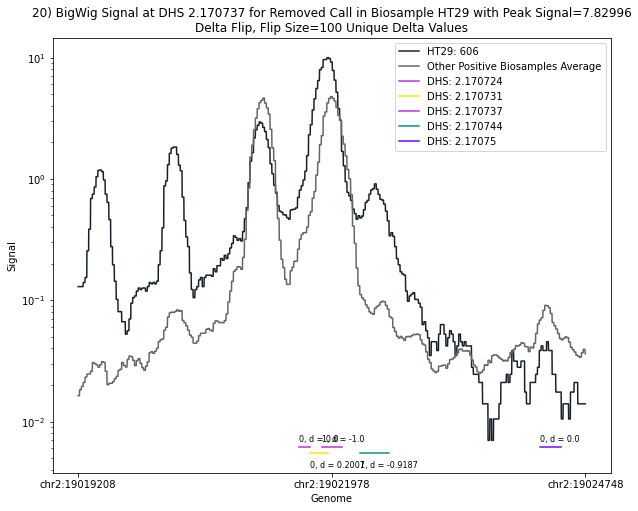

In [17]:
for i in range(20):
    plotting_signal(i)

In [16]:
def plotting_signal(i, buffer=500):
    #find biosample with call of interest
    biosample = top_100_neg1_peak_signal_biosample_inds[i]
    #dhs of call of interest
    dhs = top_100_neg1_peak_signal_DHS_inds[i]
    #chrm for DHS
    chrm = top_100_neg1_peak_signal_chr[i]
    #two upstream and two downstream DHSs
    dhss_inds_to_plot = np.arange((dhs-2),(dhs+3))
    #presence or absence in original matrix
    dhss_to_plot_original_vals = cycle0_dhs_arr[biosample, dhss_inds_to_plot].astype(int)
    #delta values of calls
    dhss_to_plot_delta_vals = diff_flat[dhss_inds_to_plot + (biosample * n_DHSs)]
    #metadata for each DHS
    dhss_to_plot_df = DHS_metadata.loc[dhss_inds_to_plot]
    dhss_to_plot_comps = np.array(dhss_to_plot_df['component'])
    dhss_to_plot_comp_color = []
    for comp in dhss_to_plot_comps:
        comp_ind = np.where(comps==comp)[0]
        dhss_to_plot_comp_color.append(color[comp_ind][0])
    dhss_to_plot_names = np.array(DHS_metadata.loc[dhss_inds_to_plot]['identifier'])
    dhss_to_plot_start = np.array(DHS_metadata.loc[dhss_inds_to_plot]['start'])
    dhss_to_plot_end = np.array(DHS_metadata.loc[dhss_inds_to_plot]['end'])
    #placing DHS of interest in center
    first_dhs_start = dhss_to_plot_start[0]
    last_dhs_end = dhss_to_plot_end[-1]
    dhs_of_interest_center = int((dhss_to_plot_start[2] + dhss_to_plot_end[2])/2)
    max_dhs_dist_to_center = np.max([dhs_of_interest_center - first_dhs_start, last_dhs_end - dhs_of_interest_center])
    start = dhs_of_interest_center - buffer - max_dhs_dist_to_center
    end = dhs_of_interest_center + buffer + max_dhs_dist_to_center

    #load bw file for biosample of interest
    agnum = biosample_df.loc[biosample]['Altius Aggregation ID'][2:]
    lnnum = biosample_df.loc[biosample]['Altius Library ID']
    if lnnum[-1].isalpha():
        lnnum = lnnum[:-1]
    read_in_question_biosample_name = biosample_df.loc[biosample]['Biosample name']
    # print(agnum)
    # print(lnnum)
    filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
    bw_file = pyBigWig.open(filename)
    read_in_question = bw_file.values(chrm, 
                                      start, 
                                      end, 
                                      numpy=True)
    
    #finding all biosamples positive for call of interest and removing biosample of interest 
    other_positive_biosamples = np.where(cycle0_dhs_arr[:, dhs]==True)[0]
    other_positive_biosamples = other_positive_biosamples[other_positive_biosamples!=biosample]
    
    #load bw file for all positive biosamples
    base_signal_values = []
    for base_biosample in other_positive_biosamples: 
        agnum = biosample_df.loc[base_biosample]['Altius Aggregation ID'][2:]
        lnnum = biosample_df.loc[base_biosample]['Altius Library ID']
        if lnnum[-1].isalpha():
            lnnum = lnnum[:-1]
        base_read_biosample_name = biosample_df.loc[base_biosample]['Biosample name']
    #     print(agnum, lnnum)
        filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
        base_read = bw_file.values(chrm, 
                                   start, 
                                   end, 
                                   numpy=True)
        base_signal_values.append(base_read)
    base_signal_values = np.array(base_signal_values)
    #bp average signal
    base_signal_values_ave = np.nanmean(base_signal_values, axis=0)
    
    #plotting
    fig = plt.figure(figsize=(10,8))
    fig.patch.set_facecolor('white')

    plt.plot(np.arange(start, end), read_in_question, color='#17202A')
    plt.plot(np.arange(start, end), base_signal_values_ave, color='#626567')
    for ind in range(5):
        if ind % 2 == 0:
            line_height = 0.0062
        else:
            line_height = 0.0055
        plt.plot(np.arange(dhss_to_plot_start[ind], dhss_to_plot_end[ind]), np.zeros(dhss_to_plot_end[ind] - dhss_to_plot_start[ind])+line_height, color=dhss_to_plot_comp_color[ind])
        if ind % 2 == 0:
            txt_height = 0.0068
        else:
            txt_height = 0.0042
        plt.text(dhss_to_plot_start[ind], txt_height, str(dhss_to_plot_original_vals[ind]) + ', d = ' + str(np.round(dhss_to_plot_delta_vals[ind], 4)), fontsize=8)

    plt.xticks([start, int((end+start)/2), end],
                 [chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])

    plt.legend([read_in_question_biosample_name + ': ' + str(biosample), 
                'Other Positive Biosamples Average',
                'DHS: ' + dhss_to_plot_names[0],
                'DHS: ' + dhss_to_plot_names[1],
                'DHS: ' + dhss_to_plot_names[2],
                'DHS: ' + dhss_to_plot_names[3],
                'DHS: ' + dhss_to_plot_names[4],])
    plt.yscale('log')
    plt.xlabel('Genome')
    plt.ylabel('Signal')
    plot_title = '%s) BigWig Signal at DHS %s for Removed Call in Biosample %s with Peak Signal=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %((i+1), dhss_to_plot_names[2], read_in_question_biosample_name, top_100_peak_scores[i])
    print(plot_title)
    plt.title(plot_title)
    plt.show()